# EDA & Visualisations

## 1. Setup

### 1.1. Importing Libraries

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import contextily as ctx
import pandas as pd

### 1.2. Loading in Analysis-Ready Dataset

In [3]:
analysis_ready_path = '/Users/callumhall/Documents/Dissertation/Datasets/final_analysis_gdf.gpkg'
analysis_gdf = gpd.read_file(analysis_ready_path)

print("Analysis-ready data loaded successfully.")

Analysis-ready data loaded successfully.


## 2. Data Characterisation

### 2.1. Greenspace Variables & SAMHI


Descriptive Statistics for Greenspace Variables:
       distance_to_greenspace  greenspace_area_in_500m  \
count             4756.000000             4.756000e+03   
mean               143.643784             9.611217e+04   
std                120.536419             1.079615e+05   
min                  0.000000             0.000000e+00   
25%                 52.700440             2.743352e+04   
50%                123.395928             6.202976e+04   
75%                205.884012             1.262361e+05   
max               1104.162938             1.149916e+06   

       greenspace_accessibility    park_equity  SAMHI_Score  
count              4.756000e+03    4756.000000  4756.000000  
mean               1.792626e+08   27626.466105    -0.265485  
std                6.997863e+08   31564.522315     0.536722  
min                0.000000e+00       0.000000    -2.006191  
25%                1.561442e+03    9708.073753    -0.623902  
50%                4.874870e+03   17721.026716    -0.30

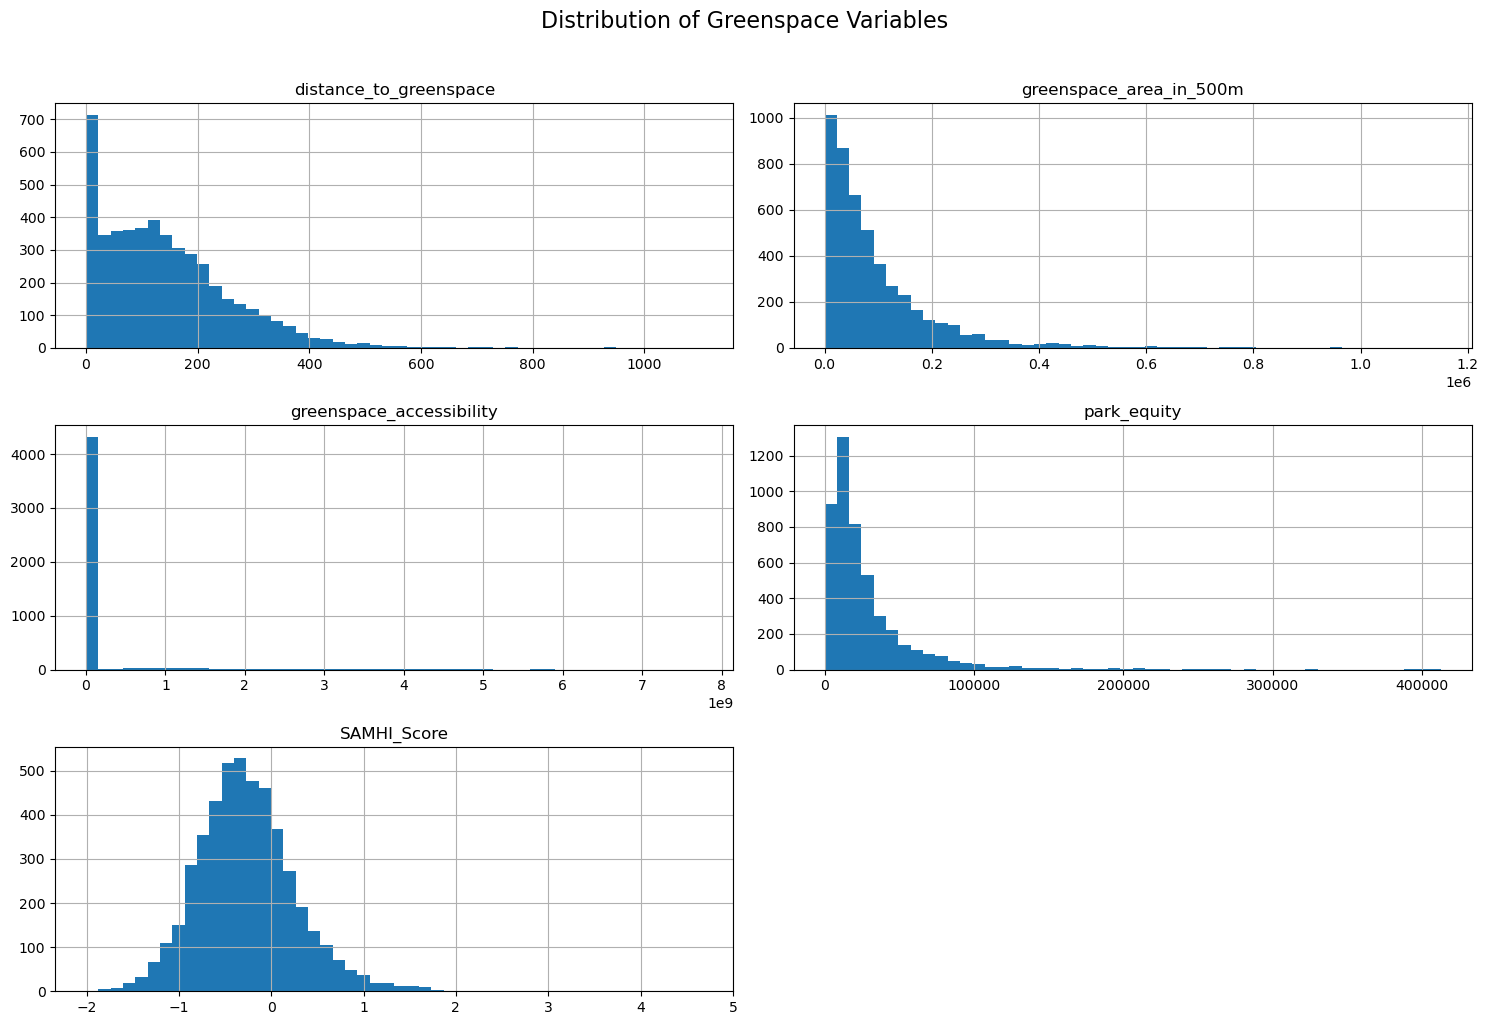

In [9]:
greenspace_vars = [
    'distance_to_greenspace',
    'greenspace_area_in_500m',
    'greenspace_accessibility',
    'park_equity',
    'SAMHI_Score'
]

print("\nDescriptive Statistics for Greenspace Variables:")
print(analysis_gdf[greenspace_vars].describe())

analysis_gdf[greenspace_vars].hist(bins=50, figsize=(15, 10))
plt.suptitle('Distribution of Greenspace Variables', size=16, y=1.02)
plt.tight_layout()
plt.show()

#### Interpretation
##### `distance_to_greenspace`:
- Average London LSOA is only 144m from nearest green space.
- Standard Deviation is large (121m) and range is extreme (from 0m to 1,184m), showing most neighbourhoods are close to some form of green space and a significant number are very far away.

##### `greenspace_area_in_500m`:
- Average greenspace is within a 5 min walk is substantial (95,824m²).
- Standard Deviation is larger than mean (108,027), showing inequality.
- Some have 0 green space, while others are next to enormous parks of over 1.1m²

##### `greenspace_accessibility`:
- Standard deviation is 4 times larger than the mean.
- Maximum value is much bigger than the 75th percentile.
- Distribution is extremely right-skewed. Small number of neighbourhoods with exceptional green space access are statistical outliers that pull the average up. The median experience of green space accessibility is far more modest than mean would suggest.

##### `park_equity`:
- Score designed to measure environmental justice (more green space in deprived areas = higher score).
- Wide & Skewed distribution, like the accessibility index.
- Mean (27, 576) much higher than median (17,643)

##### Overall Conclusion
- High variability & significant inequality.
- Inherent inequality is a critical finding and provides justification for why a LSOA level RF model is necessary to uncover the true relationships between these variables & mental health outcomes.

### 2.2. Socioeconomic Status


Descriptive Statistics for Socioeconomic Variables:
         IMD_Score  Income_Deprivation_Score  education_low  \
count  4756.000000               4756.000000    4756.000000   
mean     21.476381                  0.136357       0.241270   
std      10.911171                  0.075598       0.087443   
min       2.326000                  0.008000       0.025355   
25%      12.386500                  0.075000       0.174550   
50%      20.359500                  0.125000       0.244860   
75%      29.541250                  0.189000       0.308793   
max      64.677000                  0.437000       0.486500   

       professional_ratio  
count         4756.000000  
mean             0.399783  
std              0.112475  
min              0.141058  
25%              0.307249  
50%              0.397862  
75%              0.488308  
max              0.712430  


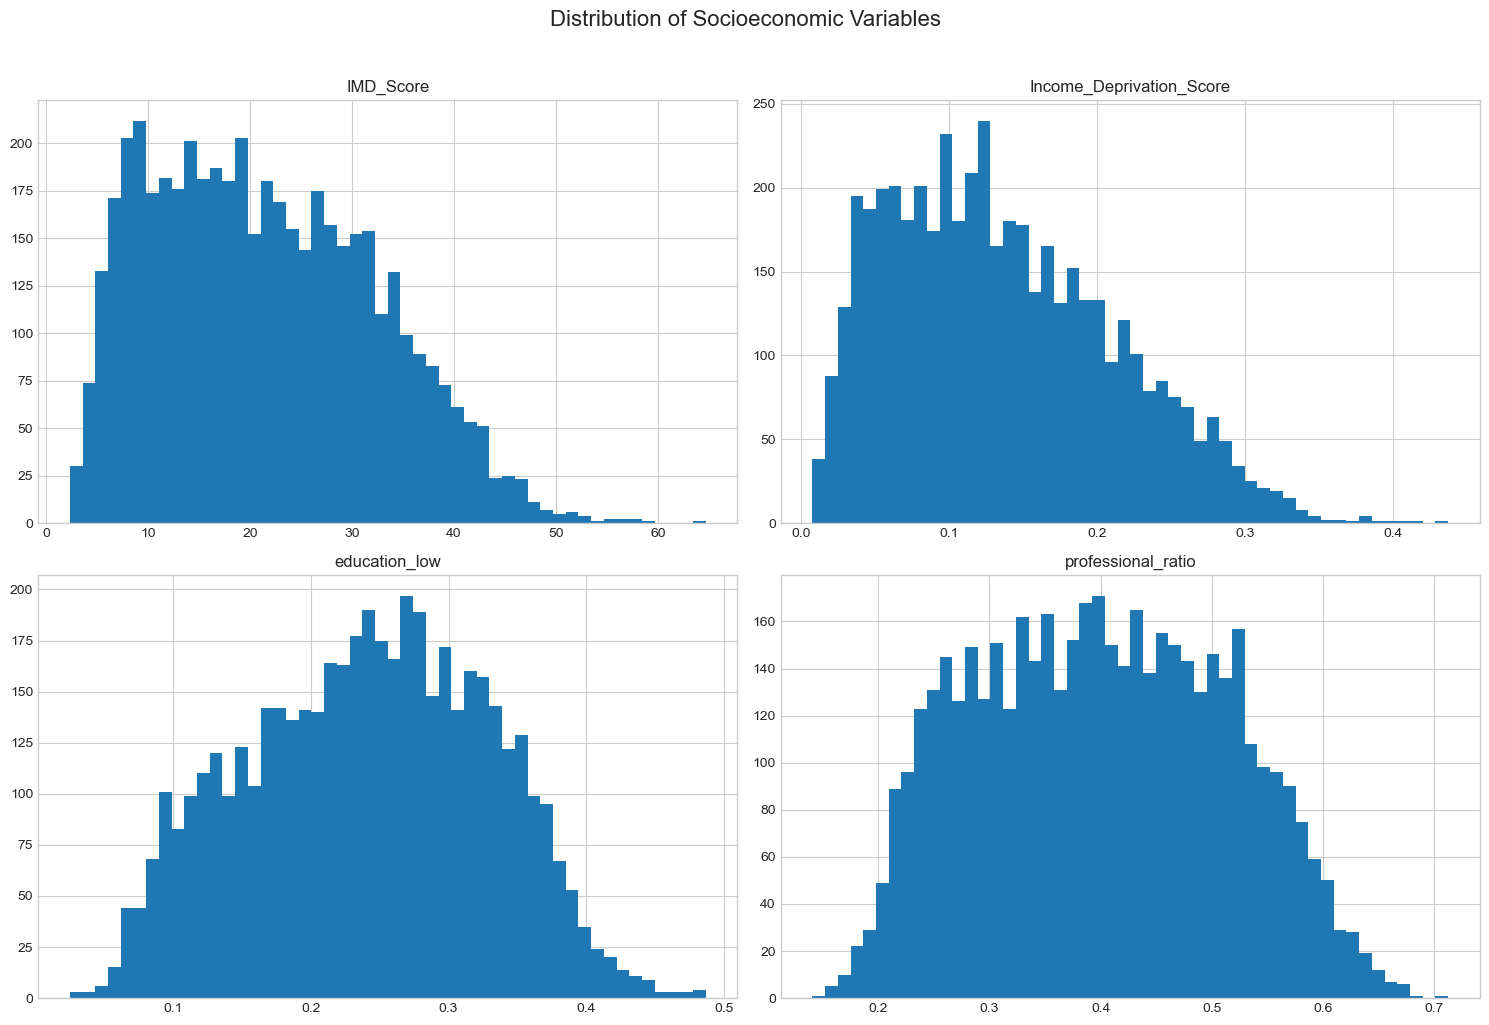

In [266]:
socio_econ_vars = [
    'IMD_Score',
    'Income_Deprivation_Score',
    'education_low',
    'professional_ratio'
]

print("\nDescriptive Statistics for Socioeconomic Variables:")
print(analysis_gdf[socio_econ_vars].describe())

analysis_gdf[socio_econ_vars].hist(bins=50, figsize=(15, 10))
plt.suptitle('Distribution of Socioeconomic Variables', size=16, y=1.02)
plt.tight_layout()
plt.show()

#### Interpretation
##### `IMD_Score`:
- The Index of Multiple Deprivation (IMD) shows a massive range from a low of 2.3 to a high of 64.7.
- Average neighbourhood score is 21.5 but the large standard deviation (10.9) shows this average is not representative.
- London contains some of the wealthiest and most deprived neighbourhoods in the country.

##### `education_low`:
- Represents the proportion of the population with low or no qualifications, showing significant variation.
- The average is only 24%, range spans from 2.5% to 48.7%.
- Highlights deep educational divides that exist within the city, which often correlate to economic outcomes.

##### `professional_ratio`:
- Average neighbourhood has around 40% of its population in professional occupations.
- Standard deviation is large (11.2%) and the range is substantial, from 14% to 71%.
- Shows stark geograpgic sorting of professional and working-class populations, which is a key driver of the other inequalities observed.

##### Conclusion:
- Shows neighbourhoods have vastly different levels of deprivation, educational attainment & professional opportunity.
- Inherent inequality justifies need for model which can move beyond simple city-wide averages to understand complex and varied conditions shape mental health outcomes.

## 2.3. Urban Environment

In [7]:
# --- 1. Calculate a threshold based on the 99th percentile ---
# This means we will keep 99% of the data and remove the top 1% of extreme outliers.
crime_threshold = analysis_gdf['crime_rate'].quantile(0.99)

print(f"The 99th percentile for crime rate is: {crime_threshold:.2f}")
print(f"Any LSOA with a crime rate higher than this will be removed.")

# --- 2. Get the original number of rows for comparison ---
original_rows = len(analysis_gdf)
print(f"Original number of LSOAs: {original_rows}")

# --- 3. Filter the DataFrame to remove the outliers ---
analysis_gdf = analysis_gdf[analysis_gdf['crime_rate'] < crime_threshold]

# --- 4. Get the new number of rows ---
new_rows = len(analysis_gdf)
print(f"New number of LSOAs after removing top 1% outliers: {new_rows}")
print(f"Removed {original_rows - new_rows} outlier LSOA(s).")

The 99th percentile for crime rate is: 810.94
Any LSOA with a crime rate higher than this will be removed.
Original number of LSOAs: 4805
New number of LSOAs after removing top 1% outliers: 4756
Removed 49 outlier LSOA(s).



Descriptive Statistics for Urban Environment Variables:
       population_density   flat_ratio   crime_rate  rented_ratio
count         4756.000000  4756.000000  4756.000000   4756.000000
mean          8112.610464     0.361685   134.097114      0.508992
std           5133.110163     0.265803   102.234521      0.208105
min             99.245502     0.000000     0.000000      0.035026
25%           4416.651132     0.142250    70.030025      0.357662
50%           7019.731166     0.301095   105.977632      0.528996
75%          10970.017568     0.538945   161.214882      0.672651
max          62899.020890     0.995798   802.083333      0.960000


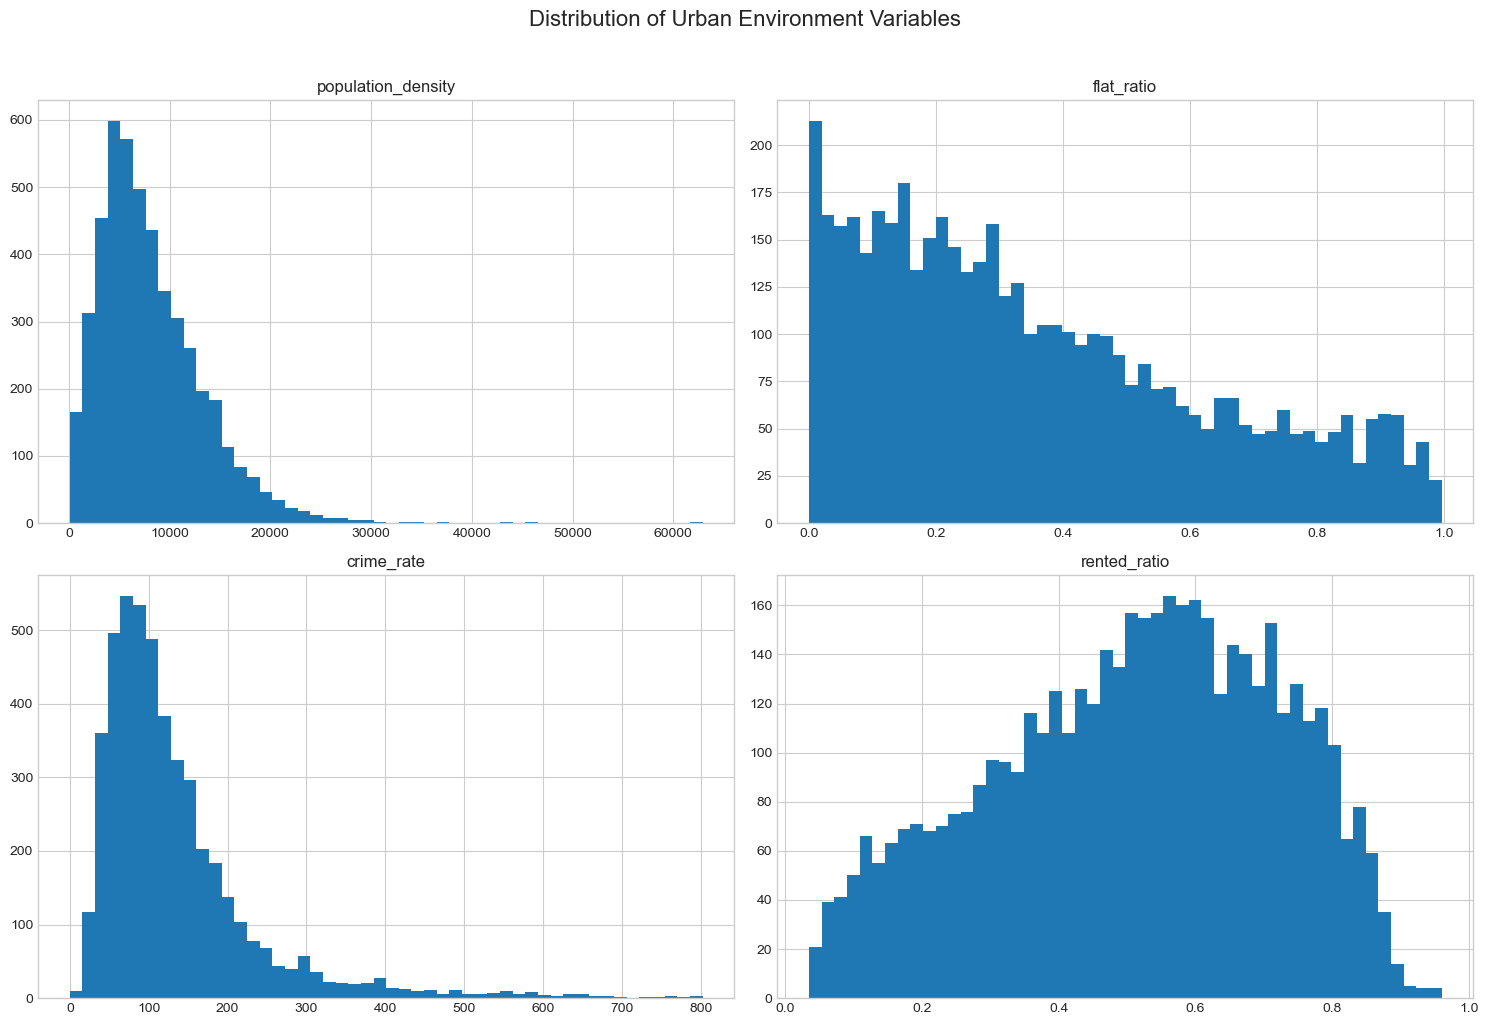

In [268]:
urban_env_vars = [
    'population_density',
    'flat_ratio',
    'crime_rate',
    'rented_ratio'
]

print("\nDescriptive Statistics for Urban Environment Variables:")
print(analysis_gdf[urban_env_vars].describe())

analysis_gdf[urban_env_vars].hist(bins=50, figsize=(15, 10))
plt.suptitle('Distribution of Urban Environment Variables', size=16, y=1.02)
plt.tight_layout()
plt.show()

#### Interpretation
##### `population_density`:
- London is on average a densely populated city, with 8,112 people per square km.
- Average hides a vast range, from 99 people/km² to 62,899 people/km².
- Variation proves a 'one-size fits all' approach to urban policy is unlikely to succeed. The lived experience of urban density is very different from one neighbourhood to the next.

##### `flat_ratio`:
- On average, 36% of properties are flats but ranges from 0% to 100%.
- Powerful proxy for urban form, distinguishing low-density terraced neighbourhoods and high-density estates which often have different social and environmental characteristics.

##### `crime_rate`:
- Average is 134 per 1000 people, the standard deviation is large (102) and range is huge (0 to 802).
- Dramatic variation suggests risk of being a victim of crime is highly concentrated in specific parts of the city.

##### `rented_ratio`:
- On average, 51% of all households in London are rented.
- Ranges from 3.5% to 96%, highlighting deep divide between stable, owner-occupied areas and more transient, rental-dominated neighbourhoods.

##### Conclusion:
- Shows neighbourhoods differ in physical density, housing type, perceived safety & housing stability.
- Variability is not random noise, it is fundamental context in which mental health outcomes are formed.
- Statistics demonstrate to understand health in London, one must understand the different environments in which Londoners live.

### 2.4. Demographics


Descriptive Statistics for Demographic Variables:
       pct_working_age  ethnic_diversity  pct_elderly    Pct_Asian  \
count      4756.000000       4756.000000  4756.000000  4756.000000   
mean          0.639654          0.945892     0.047553     0.245760   
std           0.067841          0.194867     0.013019     0.205840   
min           0.415429          0.167258     0.007178     0.007488   
25%           0.593208          0.818123     0.039057     0.105657   
50%           0.629338          0.984047     0.046687     0.170143   
75%           0.681608          1.099702     0.055805     0.301918   
max           0.930410          1.297751     0.131158     1.100986   

         Pct_White    Pct_Black  
count  4756.000000  4756.000000  
mean      0.681426     0.166234  
std       0.228954     0.137980  
min       0.025128     0.000000  
25%       0.517304     0.062722  
50%       0.691316     0.122207  
75%       0.858209     0.231963  
max       1.256260     0.778150  


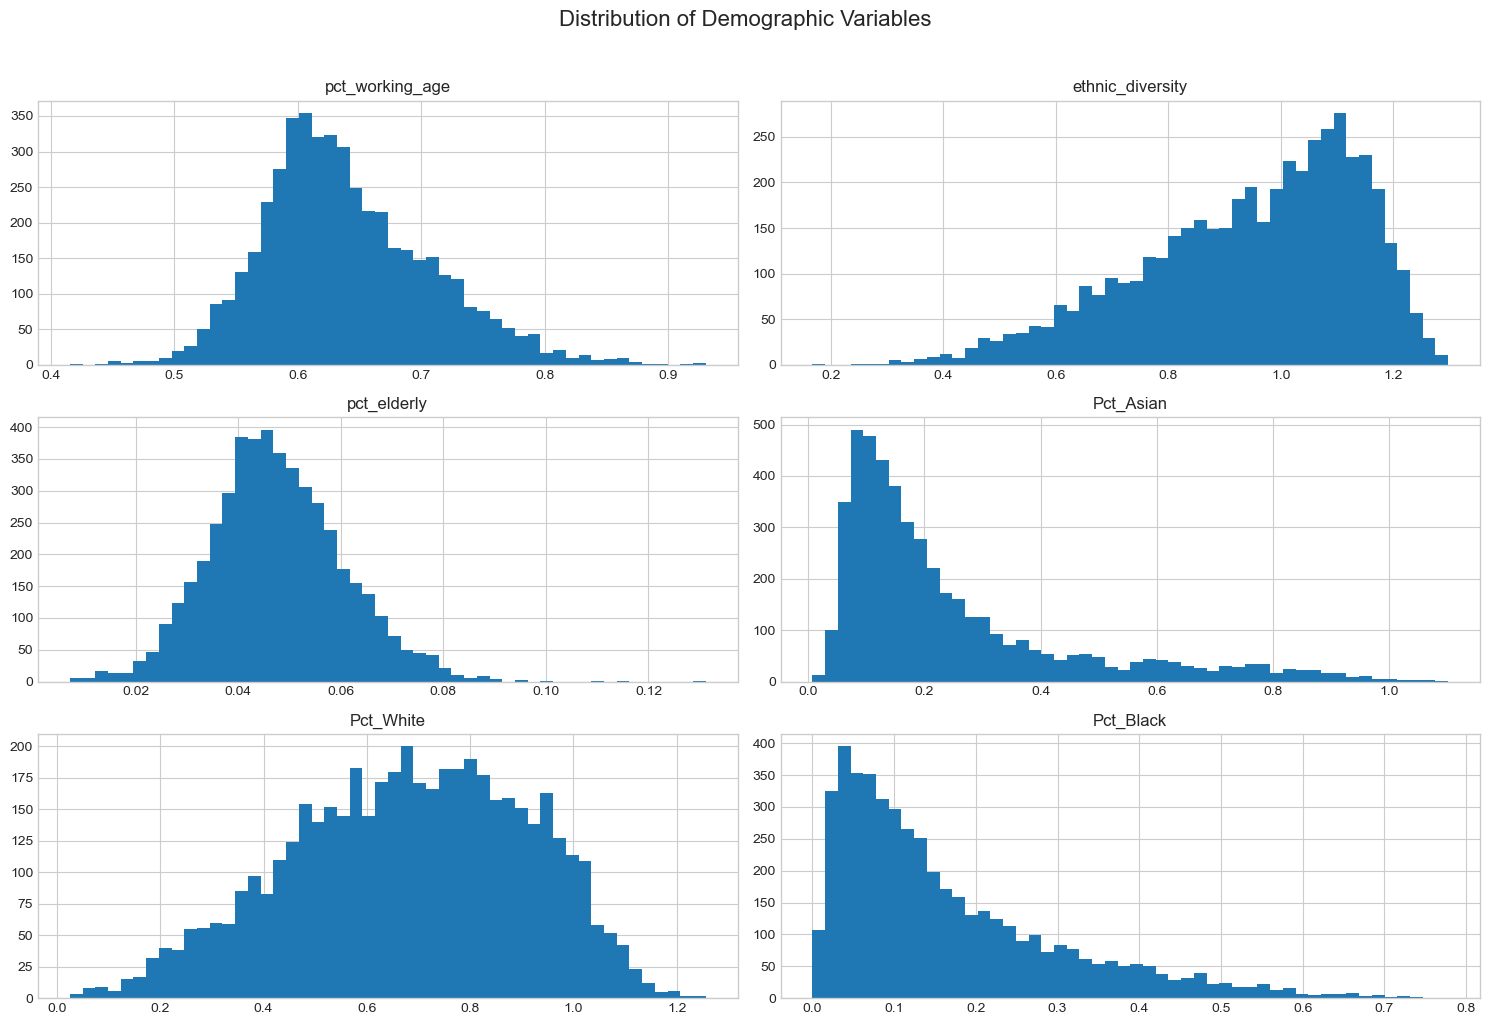

In [270]:
demographic_vars = [
    'pct_working_age',
    'ethnic_diversity',
    'pct_elderly',
    'Pct_Asian',
    'Pct_White',
    'Pct_Black'
]

print("\nDescriptive Statistics for Demographic Variables:")
print(analysis_gdf[demographic_vars].describe())

analysis_gdf[demographic_vars].hist(bins=50, figsize=(15, 10))
plt.suptitle('Distribution of Demographic Variables', size=16, y=1.02)
plt.tight_layout()
plt.show()

#### Interpretation:
##### `pct_working_age` & `pct_elderly`:
- On average, 64% of London neighbourhoods are of working age, while only 4.8% are elderly.
- Paints picture of London as an economic hub, attracting large working-age population while having a relatively smaller older population compared to other parts of the UK.
- Low standard dveiation suggests the consistency pattern across most of the city.

##### `ethnic_diversity` (Shannon Index):
- Average diversity score is 0.95 (score above 1.0 is considered high).
- Median of 0.98 and a 75th percentile of 1.1, confirms majority of London neighbourhoods are highly ethnically diverse.

##### `Pct_Asian`, `Pct_White`, `Pct_Black`:
- The city is diverse overall, percentages show specific groups aren't evenly distributed.
- The average neighbourhood has a 24.6% Asian population, ranges from 1% to 100%.
- Similarly, Black population averages 16.6% but can be as high as 78%.
- Demonstrates geographic clustering of different ethnic communities, a key social pattern.

### 2.5. Spatial Dependence


Descriptive Statistics for Spatial Dependence Variables:
       IMD_neighborhood  crime_neighborhood
count       4752.000000         4752.000000
mean          21.383175          156.487802
std            8.604471          170.115127
min            2.751000           35.546613
25%           14.108958           96.742624
50%           21.346917          127.827333
75%           27.910775          172.603787
max           51.153200         4100.609402


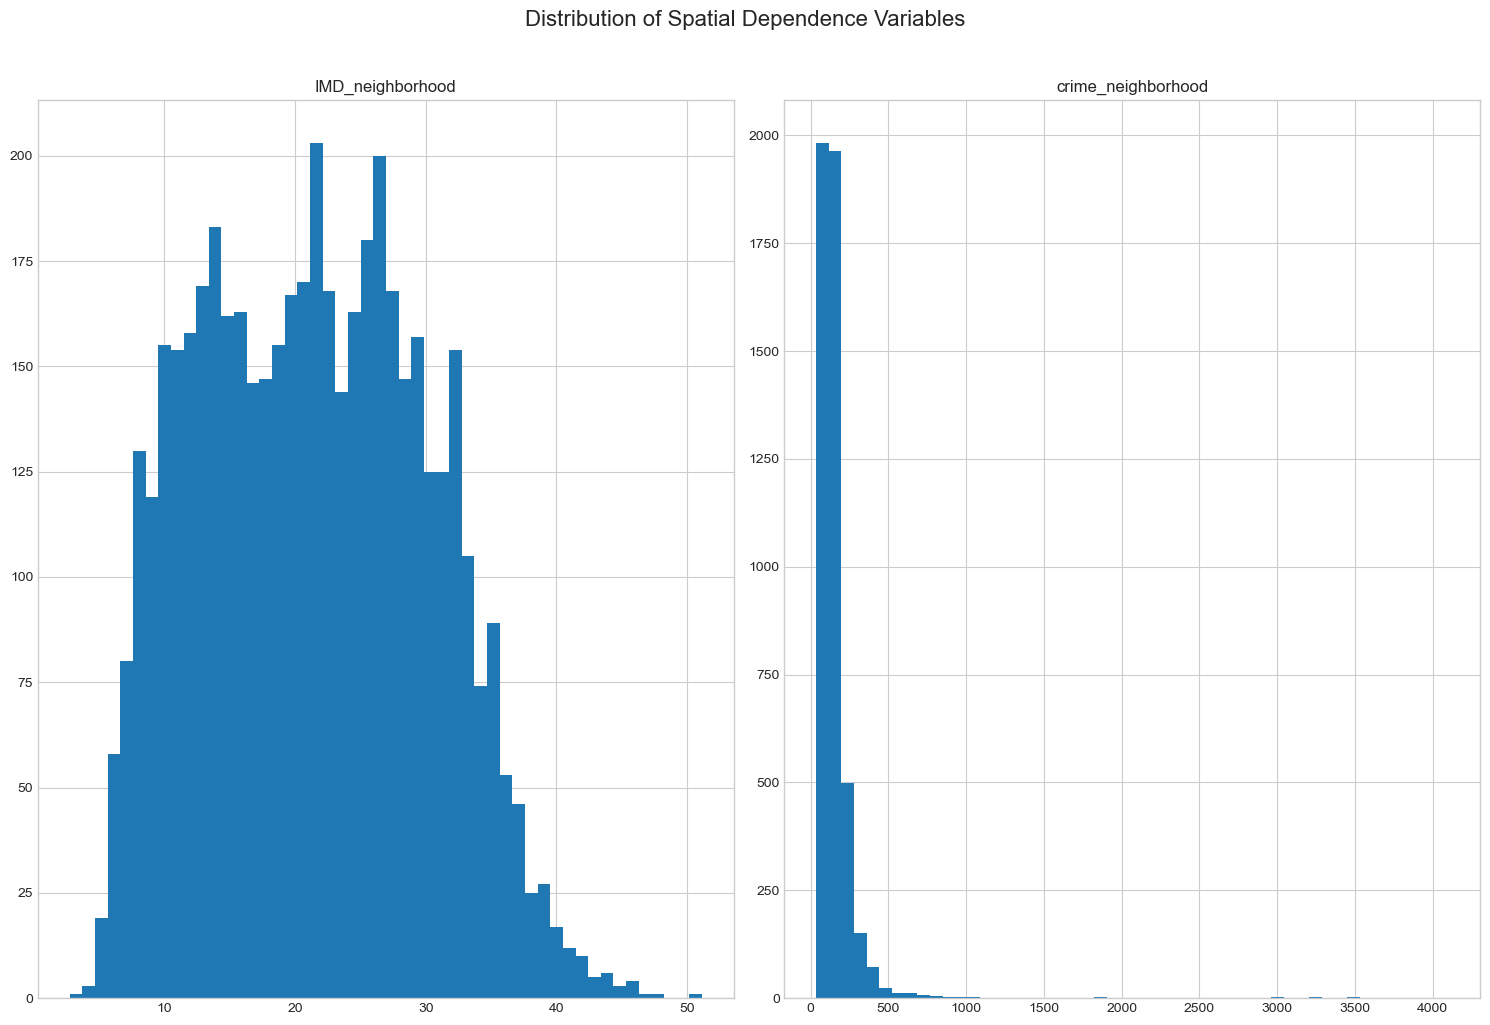

In [272]:
spatial_dependence_vars = [
    'IMD_neighborhood',
    'crime_neighborhood'
]

print("\nDescriptive Statistics for Spatial Dependence Variables:")
print(analysis_gdf[spatial_dependence_vars].describe())

analysis_gdf[spatial_dependence_vars].hist(bins=50, figsize=(15, 10))
plt.suptitle('Distribution of Spatial Dependence Variables', size=16, y=1.02)
plt.tight_layout()
plt.show()

#### Interpretation
##### `IMD_neighborhood` (Spatial Lag of Deprivation):
- This variable measures average deprivation score of a neighbourhood's immediate neighbours.
- The mean (21.4) is almost identical to the mean of `IMD_Score` of the neighbourhoods themselves, showing positive spatial autocorrelation.
- Shows deprived areas are typically located next to other deprived areas and affluent areas are next to other affluent areas.
- Model needs this to understand why neighbourhood's context is defined not just by its own conditions, but by the wider area it sits within.

##### `crime_neighbourhood`:
- Measures the average crime rate of surrounding neighbourhoods.
- Wide range, from 35.5 to 4,100, demonstrating crime is not evenly distribute. This shows there are intense crime hotspots (like the West End) whose influence spills over, creating a high crime environment for the LSOAs adjacent to them.
- The standard deviation (170) is larger than the mean (156), confirming this is a highly skewed phenomenon driven by these hotspots.

##### Conclusion:
- Prove you cannot treat London's neighbourhoods as independent islands, the 'neighbour effect' is a real and measurable force.
- Mental health is deeply intertwined in health, wealth and safeties of the surrounding communities.

## 3. Exploring Relationships

### 3.1. Correlation Plot

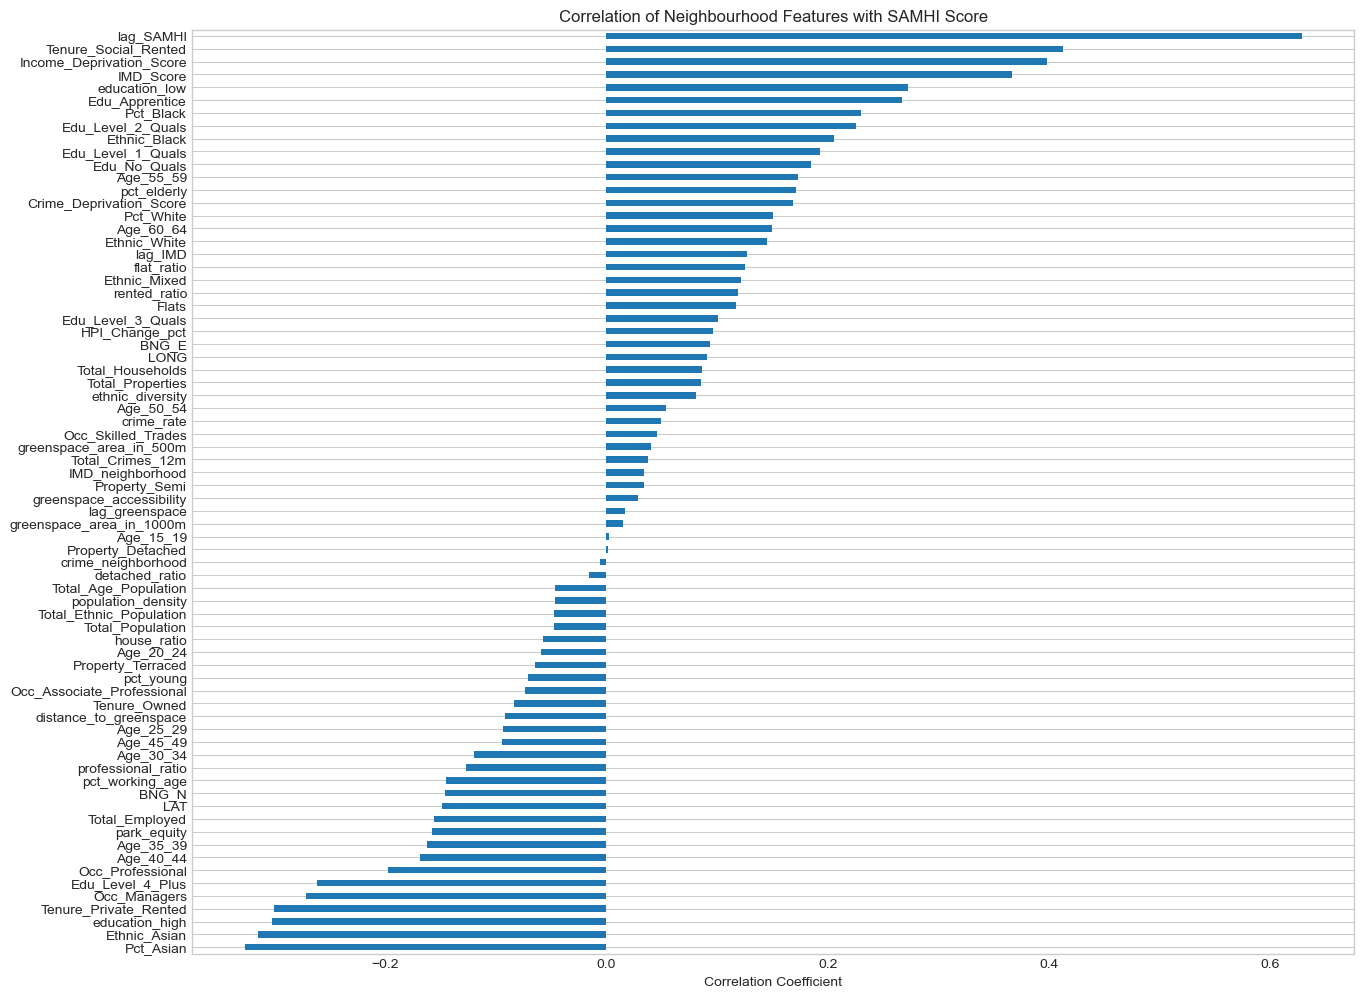

Full List of Correlations with SAMHI Score:
Pct_Asian                    -0.326472
Ethnic_Asian                 -0.314329
education_high               -0.301524
Tenure_Private_Rented        -0.299979
Occ_Managers                 -0.271390
Edu_Level_4_Plus             -0.260963
Occ_Professional             -0.197121
Age_40_44                    -0.167719
Age_35_39                    -0.161456
park_equity                  -0.157636
Total_Employed               -0.155473
LAT                          -0.148464
BNG_N                        -0.145164
pct_working_age              -0.144917
professional_ratio           -0.126669
Age_30_34                    -0.119732
Age_45_49                    -0.093951
Age_25_29                    -0.093343
distance_to_greenspace       -0.091510
Tenure_Owned                 -0.083158
Occ_Associate_Professional   -0.073621
pct_young                    -0.070685
Property_Terraced            -0.064465
Age_20_24                    -0.058600
house_ratio         

In [395]:
numeric_cols = analysis_gdf.select_dtypes(include=['float64', 'int64'])
correlations = numeric_cols.corr()['SAMHI_Score'].sort_values()

plt.figure(figsize=(15, 12))
correlations.drop(['SAMHI_Score']).plot(kind='barh')
plt.title('Correlation of Neighbourhood Features with SAMHI Score')
plt.xlabel('Correlation Coefficient')
plt.grid(axis='x')
plt.show()

print("Full List of Correlations with SAMHI Score:")
with pd.option_context('display.max_rows', None):
    print(correlations)

#### Interpretations
##### 1. Strongest Predictors of Poor Mental Health (Positive Correlation)

The factors strongly associated with higher SAMHI scores are all related to spatial context & socio-eocnomic deprivation.

- The "Neighbour Effect" (`log_SAMHI`: 0.63): Suggests mental health outcomes are highly clustered geographically.
- Deprivation & Housing (`Tenure_Social_Rented`: 0.41, `IMD_Score`: 0.37): Provides evidence that higher levels of deprivation & more social housing have a strong linear relationship with poorer mental health outcomes.

##### 2. Strongest Predictors of Better Mental Health (Negative Correlation)

Conversely, the factors associated with lower SAMHI scores relate to demographics, education and professional status.

- Demographics (`Pct_Asian`: -0.33): Aligns with idea that Asian households may be less likely to seek or be recorded for formal mental health support, resulting in a lower SAMHI score.
- Education & Occupation (`education_high`: -0.30, `professional_ratio`: -0.13`): Neighbourhoods with a higher proportion of highly educated residents and in professional occupations show a clear negative correlation with poor mental health.

##### 3. Weakest Predictors

- Green Space (`greenspace_accessibility`: 0.03, `distance_to_greenspace`: -0.09): All green space variables show an extremely weak linear relationship with SAMHI score, suggesting link between green space and mental health is not direct and is likely confoundeed by other factors.
- Crime (`crime_rate`: 0.05): Correlation between crime & mental health is surprisingly weak.

### 3.2. The Moderating Effect of Deprivation

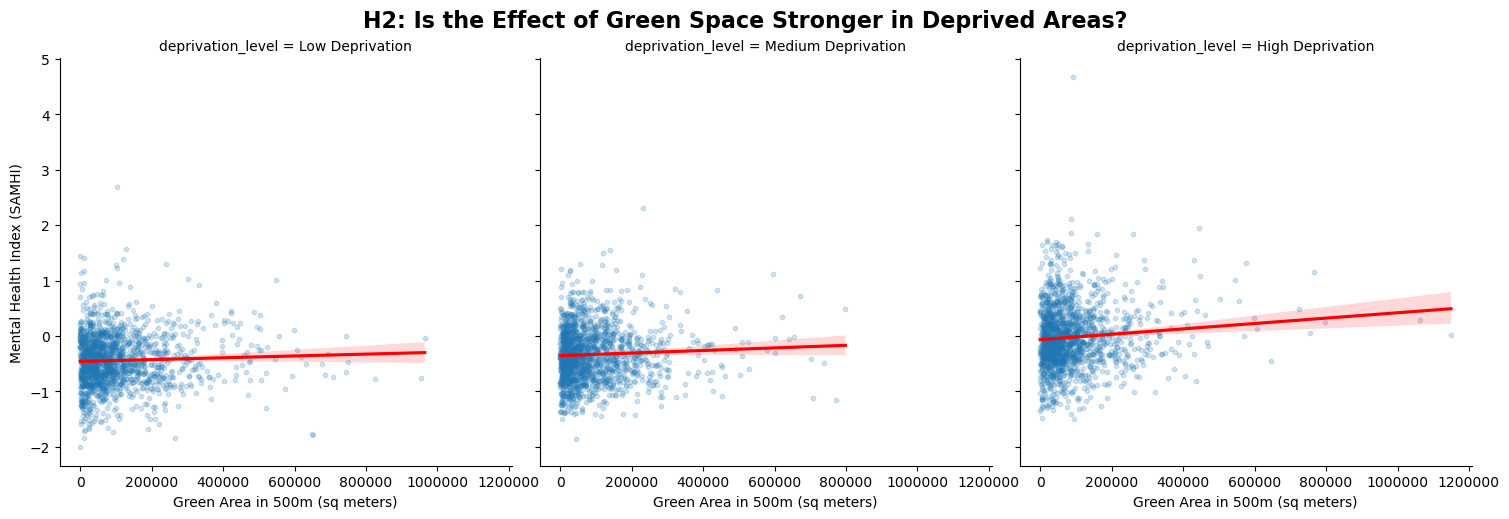

In [36]:
# --- Generate the Plot ---
# Create deprivation categories using quantiles
analysis_gdf['deprivation_level'] = pd.qcut(
    analysis_gdf['IMD_Score'],
    q=3,
    labels=['Low Deprivation', 'Medium Deprivation', 'High Deprivation']
)

# --- Your existing plotting code ---
g = sns.FacetGrid(analysis_gdf, col="deprivation_level", col_order=['Low Deprivation', 'Medium Deprivation', 'High Deprivation'], height=5)
g.map(sns.regplot, "greenspace_area_in_500m", "SAMHI_Score", scatter_kws={'alpha':0.2, 's':10}, line_kws={'color':'red'})
g.set_axis_labels("Green Area in 500m (sq meters)", "Mental Health Index (SAMHI)")
g.fig.suptitle('H2: Is the Effect of Green Space Stronger in Deprived Areas?', fontsize=16, fontweight='bold', y=1.03)

# --- Add this line to disable scientific notation on the x-axis ---
plt.ticklabel_format(style='plain', axis='x')

plt.show()

#### Interpretation
##### No Evidence of Moderating Effect:
- If H2 true, the trend line in "High Deprivation" panel would be steeper and more negative than that in the "Low Deprivation".
- Trend is almost flat across all categories.

##### Conclusion:
- Provides evidence to reject H2.
- Based on this exploration, the protective effect of UGS does not appear to be stronger in more deprived areas.

### 3.3 Raw Relationships

#### 3.3.1 Green Space vs Mental Health & Crime vs Mental Health

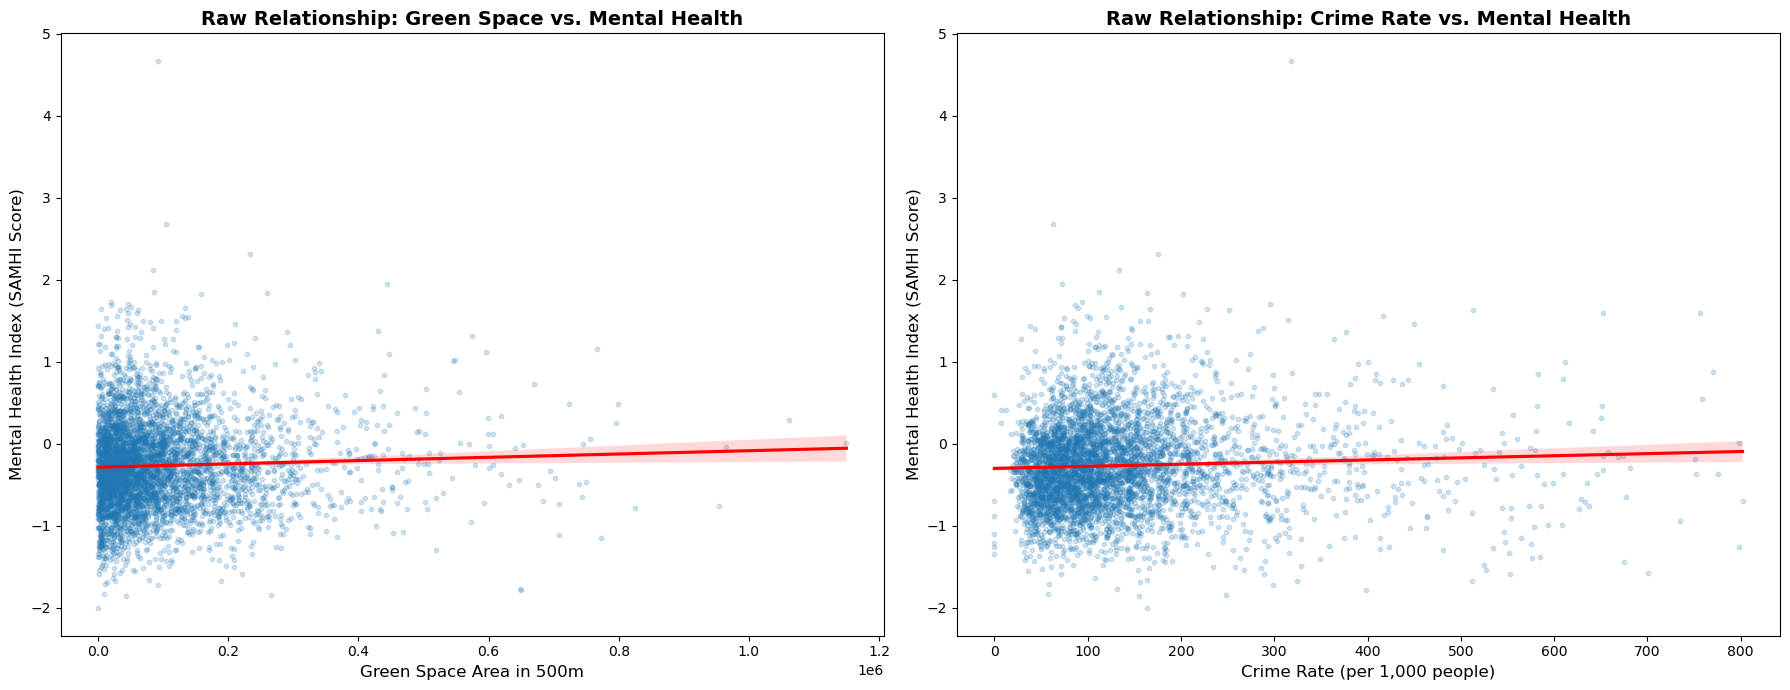

In [39]:
# --- Generate the Plots ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Green Space vs. Mental Health
sns.regplot(
    x='greenspace_area_in_500m',
    y='SAMHI_Score',
    data=analysis_gdf,
    scatter_kws={'alpha':0.2, 's':10},
    line_kws={'color':'red'}, # The target line
    ax=ax1
)
ax1.set_title('Raw Relationship: Green Space vs. Mental Health', fontsize=14, fontweight='bold')
ax1.set_xlabel('Green Space Area in 500m', fontsize=12)
ax1.set_ylabel('Mental Health Index (SAMHI Score)', fontsize=12)

# Plot 2: Crime vs. Mental Health
sns.regplot(
    x='crime_rate',
    y='SAMHI_Score',
    data=analysis_gdf,
    scatter_kws={'alpha':0.2, 's':10},
    line_kws={'color':'red'}, # The target line
    ax=ax2
)
ax2.set_title('Raw Relationship: Crime Rate vs. Mental Health', fontsize=14, fontweight='bold')
ax2.set_xlabel('Crime Rate (per 1,000 people)', fontsize=12)
ax2.set_ylabel('Mental Health Index (SAMHI Score)', fontsize=12)

plt.tight_layout()
plt.show()

#### Interpretation
##### No Clear Linear Relationship:
- Lack of strong, clear trend in both and regression line is nearly flat.
- Shows no simple linear relationship between green space, crime rate & SAMHI score.

##### Justification for More Complex Model
- Justifies use of ML model to uncover direct relationship from confounders.

### 3.3.2 IMD Score & SAMHI Score

Text(0, 0.5, 'Poor Mental Health (SAMHI Score)')

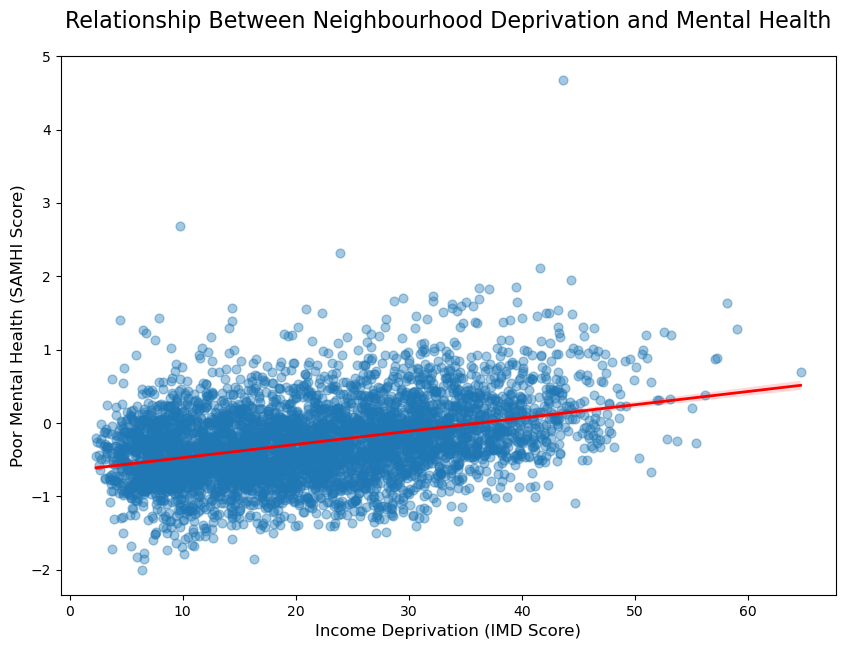

In [11]:
# Create a figure and axes for the plot
plt.figure(figsize=(10, 7))

# Create the scatter plot with a regression line (trend line) using seaborn's regplot
ax = sns.regplot(
    data=analysis_gdf,
    x='IMD_Score',
    y='SAMHI_Score',
    scatter_kws={'alpha': 0.4, 's': 40},  # Style for the scatter points
    line_kws={'color': 'red', 'linewidth': 2}  # Style for the regression line
)

# Add informative titles and labels
ax.set_title('Relationship Between Neighbourhood Deprivation and Mental Health', fontsize=16, pad=20)
ax.set_xlabel('Income Deprivation (IMD Score)', fontsize=12)
ax.set_ylabel('Poor Mental Health (SAMHI Score)', fontsize=12)

## 4. Geographic & Demographic Analysis

### 4.1. Comparing Outcomes Across Boroughs

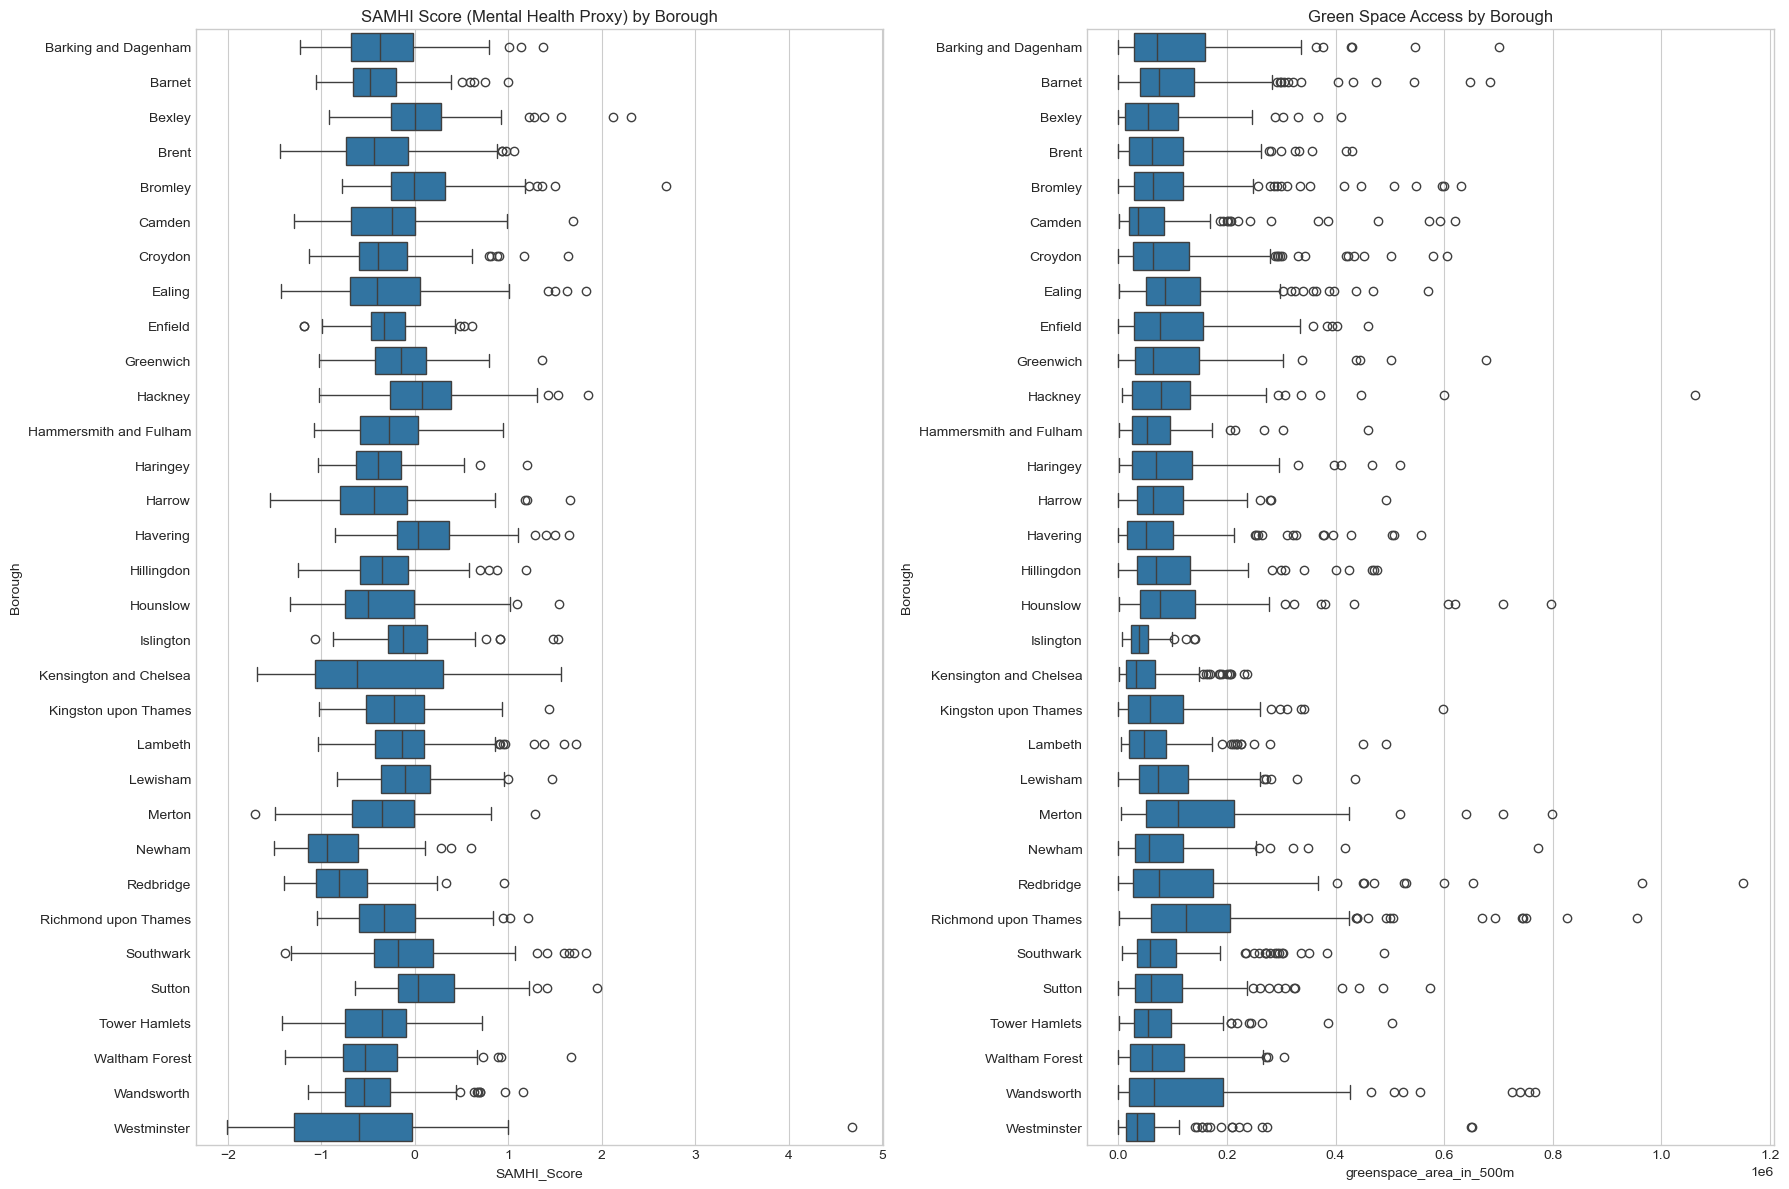

In [278]:
fig, axes = plt.subplots(1, 2, figsize=(18, 12))
sns.boxplot(ax=axes[0], data=analysis_gdf.sort_values('Borough'), y='Borough', x='SAMHI_Score', orient='h') 
axes[0].set_title('SAMHI Score (Mental Health Proxy) by Borough')
sns.boxplot(ax=axes[1], data=analysis_gdf.sort_values('Borough'), y='Borough', x='greenspace_area_in_500m', orient='h')
axes[1].set_title('Green Space Access by Borough')
plt.tight_layout()
plt.show()

#### Interpretation of SAMHI Score by Borough
##### High Median Scores:
Boroughs like Barking & Dagenham, Greenwich & Lewisham have higher SAMHI scores. Suggesting they experience a higher mental health burden, interesting as these are typically more deprived boroughs.

##### Low Median Scores:
Boroughs like Kensington & Chelsea, Richmond upon Thames & Kingston upon Thames have lower median SAMHI scores. These boroughs are considered more affluent.

##### Wide Variation:
Westminster & Camden have wide box & many outliers. Shows within boroughs, there's a huge range of outcomes - containing some of best and worst-off neighbourhoods in terms of mental health.

#### Interpretation of Green Space Access by Borough
##### High GSA:
Boroughs like Richmond upon Thames, Bromley & Hillingdon have highest median green space access (typically outer London boroughs with more large parks).

##### Low GSA:
Inner London boroughs like Kensington & Chelsea, Westminster & Islington show lowest median green space access.

#### Key Takeaways
Kensington and Chelsea has the lowest green space access but one of the best mental health outcomes. Alternatively, Greenwich has relatively good green space access but one of the worse mental health outcomes.

Shows relationship between green space & mental health is not simple. Example of K&C which is wealthy, has good mental health but low green space suggests socio-economic factors are a dominant force. This is justification for my ML model, show need to control for factors like deprivation, crime & housing costs to isolate true independent effects of green space.

### 4.2 Exploring the Relationship of the Black Population, Mental Health & Deprivation

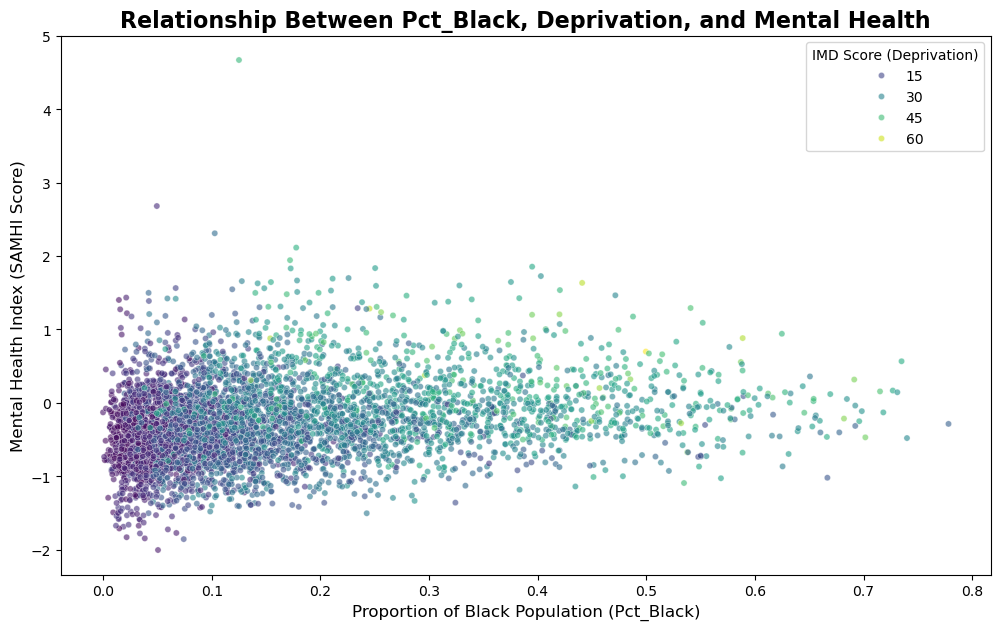

In [27]:
# --- Generate the Plot ---
plt.figure(figsize=(12, 7))
sns.scatterplot(
    x='Pct_Black',
    y='SAMHI_Score',
    data=analysis_gdf,
    hue='IMD_Score', # Color the points by deprivation
    palette='viridis',
    alpha=0.6,
    s=20
)

plt.title('Relationship Between Pct_Black, Deprivation, and Mental Health', fontsize=16, fontweight='bold')
plt.xlabel('Proportion of Black Population (Pct_Black)', fontsize=12)
plt.ylabel('Mental Health Index (SAMHI Score)', fontsize=12)
plt.legend(title='IMD Score (Deprivation)')

plt.show()

#### Interpretation
##### No Simple Relationship Between `Pct_Black` and Mental Health:
- Lack of a linear strend, the points form a wide and scattered cloud.
- Indicates knowing the proportion of Black Residents is not a straightforward predictor of an area's mental health.

##### Overwhelming Influence of Deprivation:
- Colour of points shows neighbourhoods with a higher proportion of Black residents have a higher IMD Score showing these areas have high deprivation.

### 4.3. Relationship Between the Percentage of Asian Residents & Mental Health

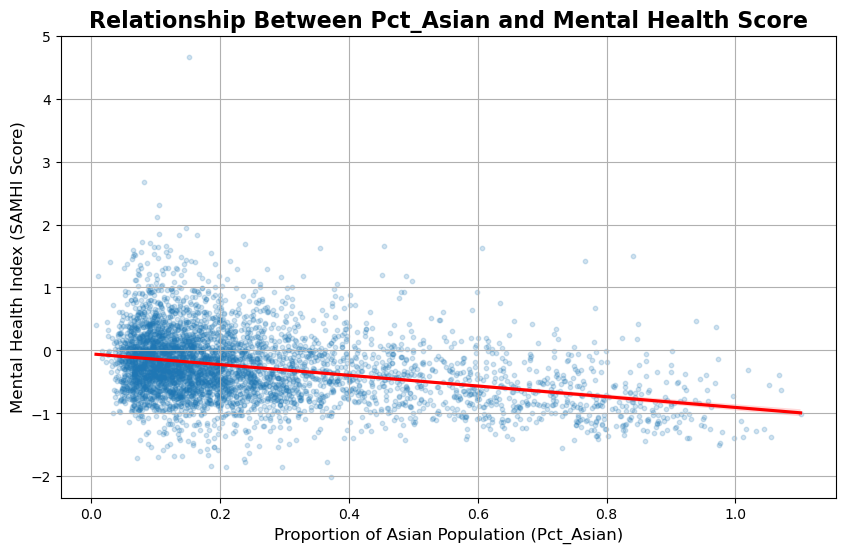

In [23]:
# --- Generate the Scatter Plot ---
plt.figure(figsize=(10, 6))
sns.regplot(
    x='Pct_Asian',
    y='SAMHI_Score',
    data=analysis_gdf,
    scatter_kws={'alpha': 0.2, 's': 10}, # Transparent points to show density
    line_kws={'color': 'red'}           # Clear trend line
)

plt.title('Relationship Between Pct_Asian and Mental Health Score', fontsize=16, fontweight='bold')
plt.xlabel('Proportion of Asian Population (Pct_Asian)', fontsize=12)
plt.ylabel('Mental Health Index (SAMHI Score)', fontsize=12)
plt.grid(True)
plt.show()

#### Interpretation
##### Negative Correlation:
- Plot shows a moderate, negative linear relationship between `Pct_Asian` and `SAMHI_Score`.
- Downward slope indicates as the percentage of Asian residents increases, the SAMHI Score decreases.

## 5. Geospatial Visualisations

### 5.1. SAMHI Score

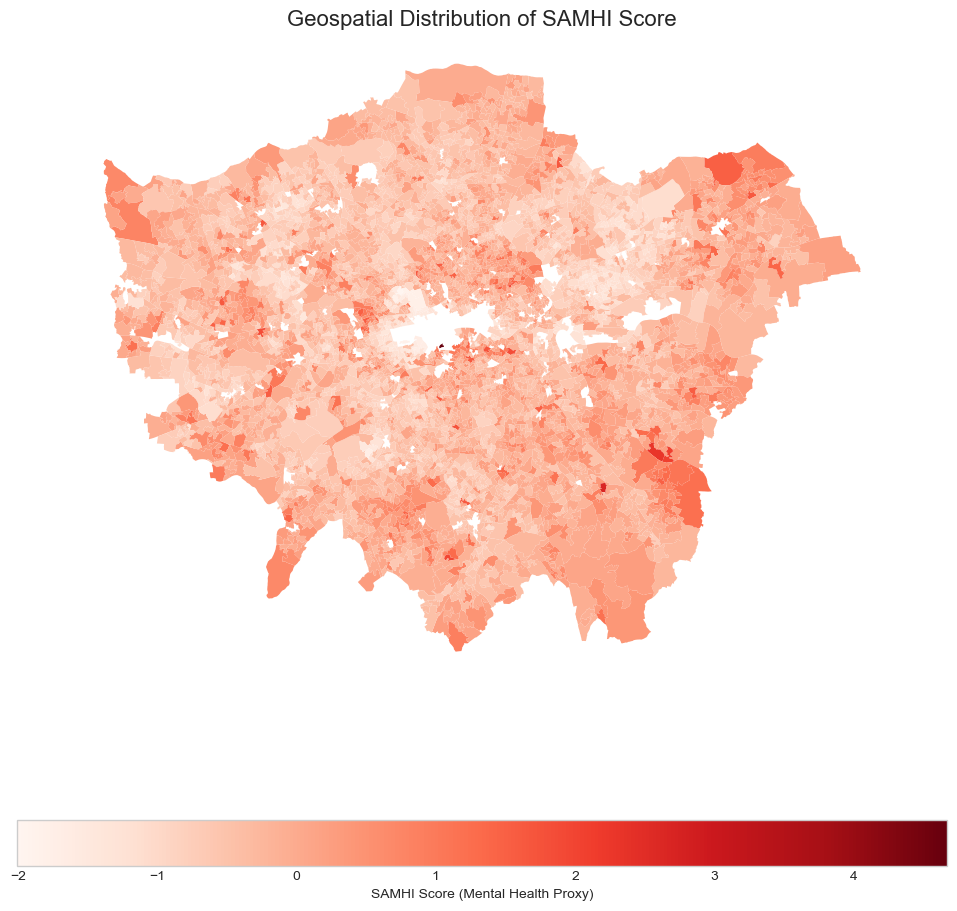

In [283]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

analysis_gdf.plot(column='SAMHI_Score', cmap='Reds', ax=ax, legend=True, 
                  legend_kwds={'label': "SAMHI Score (Mental Health Proxy)", 'orientation': "horizontal"})

ax.set_title('Geospatial Distribution of SAMHI Score', size=16)
ax.set_axis_off()
plt.show()

#### 5.1.1. Interpretation
- Spatial Clustering: Poor mental health are not randomly distributed but heavily clustered in specific parts of the city.
- Hotspots: Clear hotspots of high SAMHI scores concentrated in Inner London, stretching into East & South-East London.
- Coldspots: Areas with lower SAMHI scores in West & South-West London, particularly in boroughs like Richmond-upon-Thames & Kingston-upon-Thames (high greenspace & affluent).

#### 5.1.2. Takeaways
- Geographical inequality in mental health outcomes across the city. 

### 5.2. Greenspace

#### 5.2.1. Greenspace Area in 500m

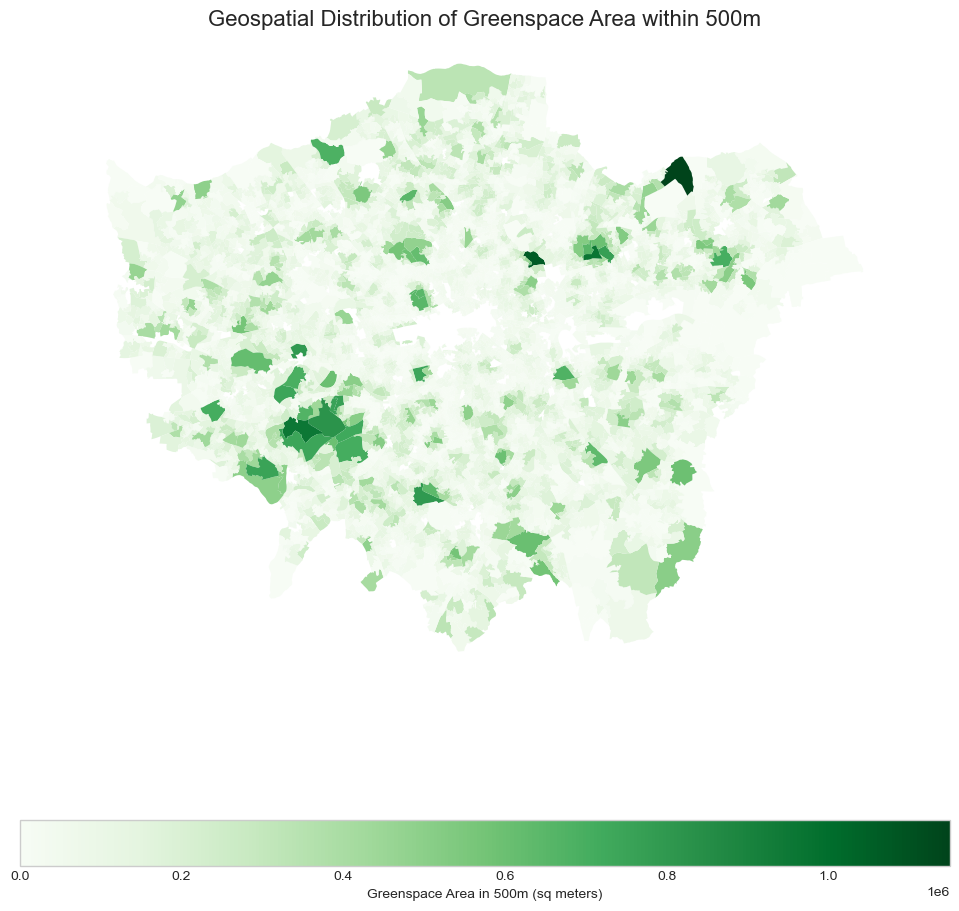

In [287]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

analysis_gdf.plot(column='greenspace_area_in_500m', cmap='Greens', ax=ax, legend=True, 
                  legend_kwds={'label': "Greenspace Area in 500m (sq meters)", 'orientation': "horizontal"})

ax.set_title('Geospatial Distribution of Greenspace Area within 500m', size=16)
ax.set_axis_off()
plt.show()

##### Interpretations
- Spatial Inequality: Clear pattern of green deprivation in dense urban core.
- Inner London vs Outer London: Palest areas are heavily concentrated in Inner London, whislt darker areas located in suburban boroughs. Prominent green clusters in areas like Richmond and near Epping Forest in the North East.

#### 5.2.2. Greenspace Accessibility

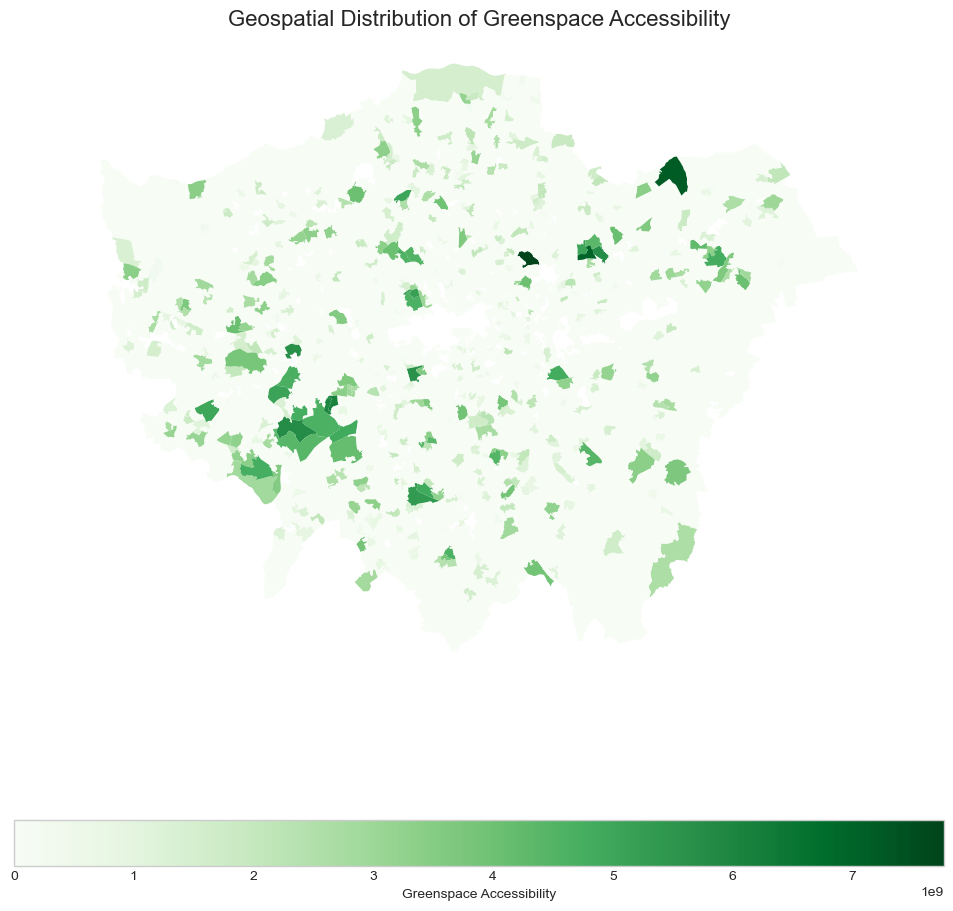

In [290]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

analysis_gdf.plot(column='greenspace_accessibility', cmap='Greens', ax=ax, legend=True, 
                  legend_kwds={'label': "Greenspace Accessibility", 'orientation': "horizontal"})

ax.set_title('Geospatial Distribution of Greenspace Accessibility', size=16)
ax.set_axis_off()
plt.show()

#### 5.2.3. Park Equity

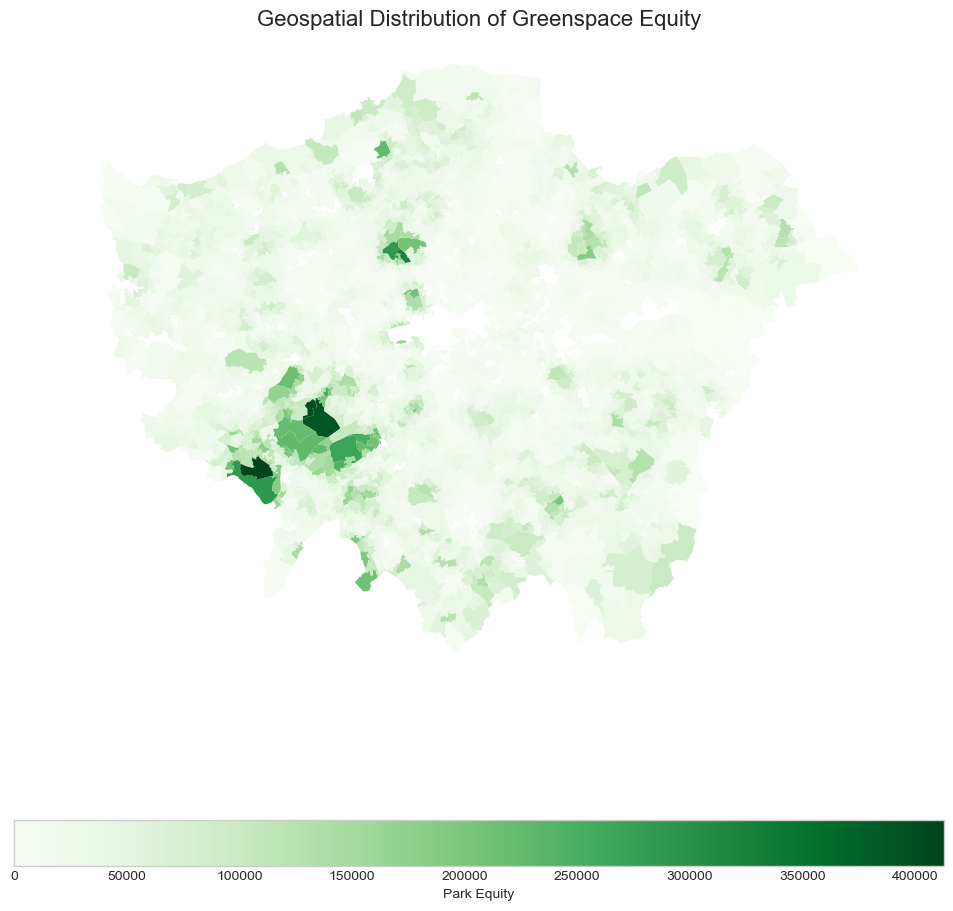

In [292]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

analysis_gdf.plot(column='park_equity', cmap='Greens', ax=ax, legend=True, 
                  legend_kwds={'label': "Park Equity", 'orientation': "horizontal"})

ax.set_title('Geospatial Distribution of Greenspace Equity', size=16)
ax.set_axis_off()
plt.show()

##### Interpretation:
- Greenspace Equity clustered around outer Southwest London (i.e. Kingston & Richmond).
- Shows affluent areas with large amounts of greenspace.}

### 5.3. Income Deprivation

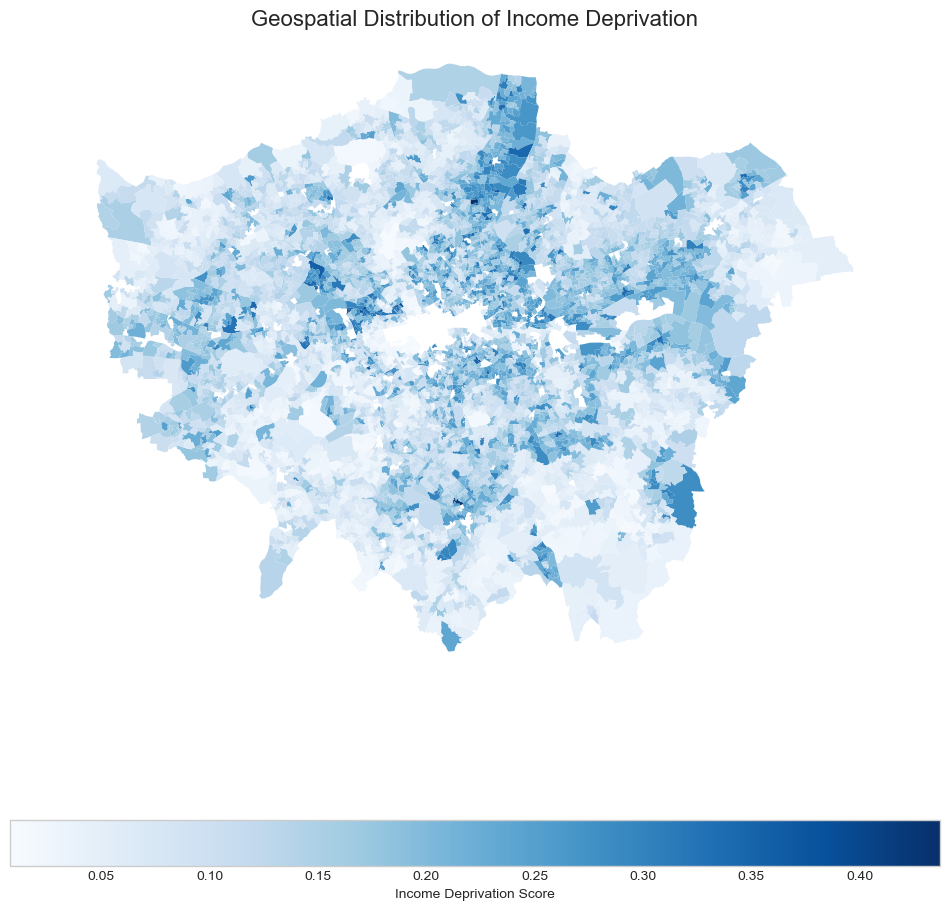

In [295]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))

analysis_gdf.plot(column='Income_Deprivation_Score', cmap='Blues', ax=ax, legend=True, 
                  legend_kwds={'label': "Income Deprivation Score", 'orientation': "horizontal"})

ax.set_title('Geospatial Distribution of Income Deprivation', size=16)
ax.set_axis_off()
plt.show()

#### 5.4.1. Interpretation
- Spatial Clustering: Income distribution heavily clusters in specific parts of the city, a classic pattern of urban inequality.
- Hotspots: Clear hotspots of high deprivation through East and South-East London, with some pockets visible in North and West London.
- Coldspots: Lowest income deprivation in West and South-West London, particularly in boroughs like Richmond-Upon-Thames, Kingston-upon-Thames and K&C.

### 5.4. Comparisons

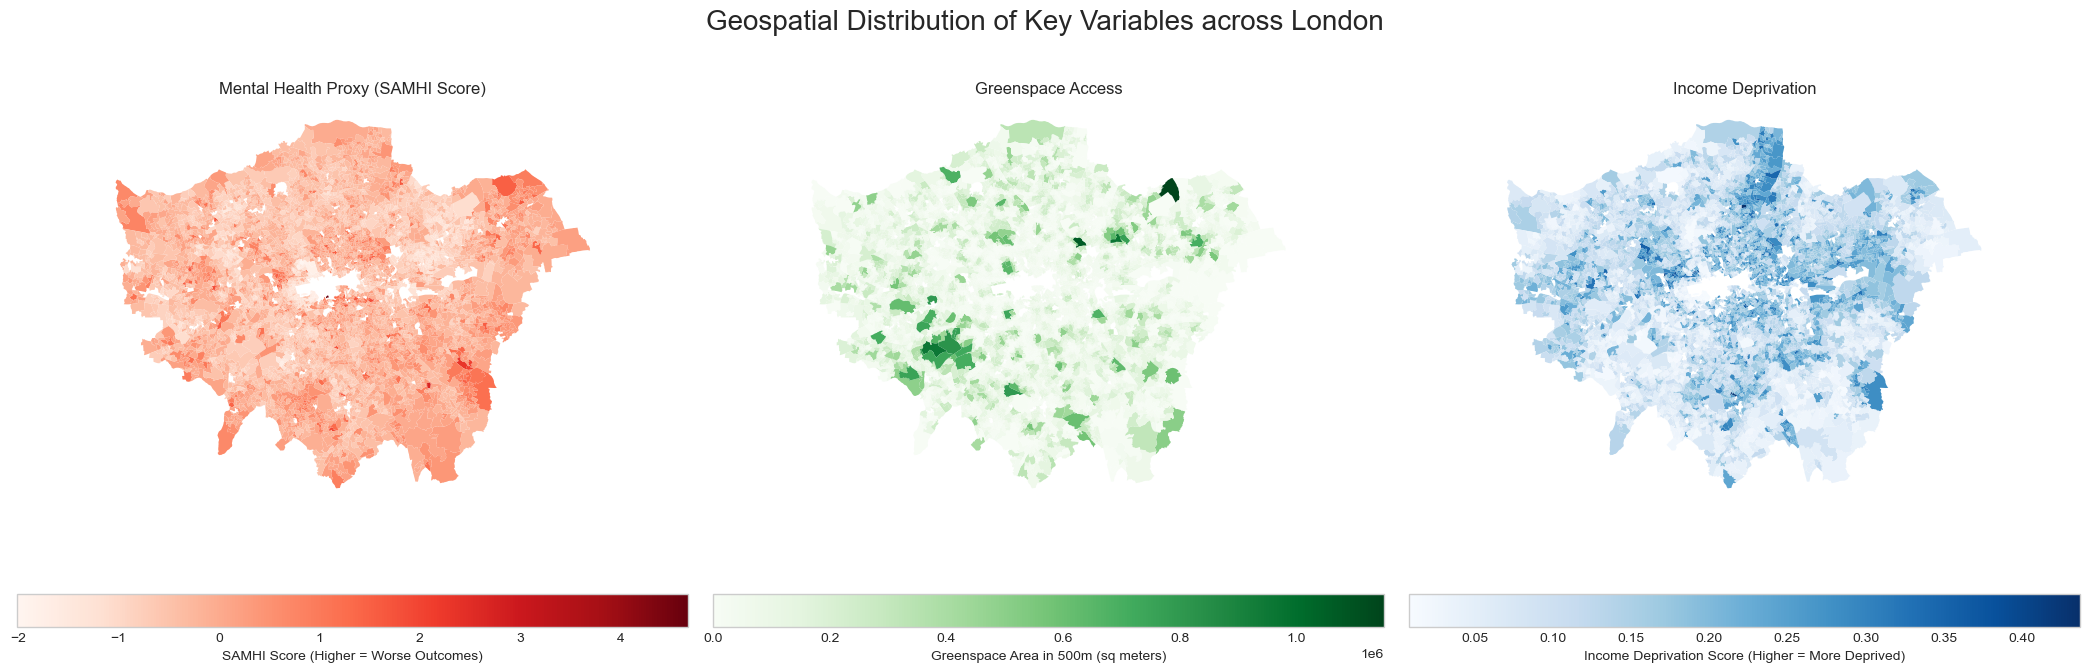

In [298]:
# This creates a figure with 1 row and 3 columns of subplots
fig, axes = plt.subplots(1, 3, figsize=(21, 7), sharex=True, sharey=True)

# --- Map 1: SAMHI Score (Mental Health Proxy) ---
analysis_gdf.plot(
    column='SAMHI_Score', 
    cmap='Reds', 
    ax=axes[0], 
    legend=True, 
    legend_kwds={'label': "SAMHI Score (Higher = Worse Outcomes)", 'orientation': "horizontal"}
)
axes[0].set_title('Mental Health Proxy (SAMHI Score)')
axes[0].set_axis_off()

# --- Map 2: Greenspace Area in 1km ---
analysis_gdf.plot(
    column='greenspace_area_in_500m', 
    cmap='Greens', 
    ax=axes[1], 
    legend=True, 
    legend_kwds={'label': "Greenspace Area in 500m (sq meters)", 'orientation': "horizontal"}
)
axes[1].set_title('Greenspace Access')
axes[1].set_axis_off()

# --- Map 3: Income Deprivation Score ---
analysis_gdf.plot(
    column='Income_Deprivation_Score', 
    cmap='Blues', 
    ax=axes[2], 
    legend=True, 
    legend_kwds={'label': "Income Deprivation Score (Higher = More Deprived)", 'orientation': "horizontal"}
)
axes[2].set_title('Income Deprivation')
axes[2].set_axis_off()

# --- Add a main title and display the plot ---
plt.suptitle('Geospatial Distribution of Key Variables across London', size=20)
plt.tight_layout(rect=[0, 0, 1, 0.95]) # Adjust layout to make space for the suptitle
plt.show()

#### 5.4.1 Comparison: A Tale of Two Londons
##### 1. The Core Spatial Pattern: An East/West Divide
- Hotspots of Distress: Areas with highest SAMHI scores are heavily concentrated though Inner, East & South-East London.
- Deprivation Clusters: These same areas are almost perfectly mirrored on the Income Deprivation map, showing a visual correlation between poverty and poor mental health outcomes.
- Green Deserts: Same hotpots of poor health and high deprivation are paler in the Greenspace Area map, indicating significantly less access to greenspace.
- Interpretation: Eastern half of the city experiences a compounding disadvantage of high deprivation, worse mental health and less access to greenspace.

##### 2. Borough-Level Story
- Boroughs in the hotspot areas on the maps (Barking & Dagenham, Greenwich, Newham, Tower Hamlets) consistenly show higher median SAMHI scores.
- Boroughs in coldspot areas (Richmond, Kingston, Kensington & Chelsea) show lower median SAMHI scores and for the outer boroughs, higher green space access.
- Interpretation: Spatial patterns are not random noise but structured  in boroughs, highlighting clear georgaphic inequalities in both environmental amenities and public health.

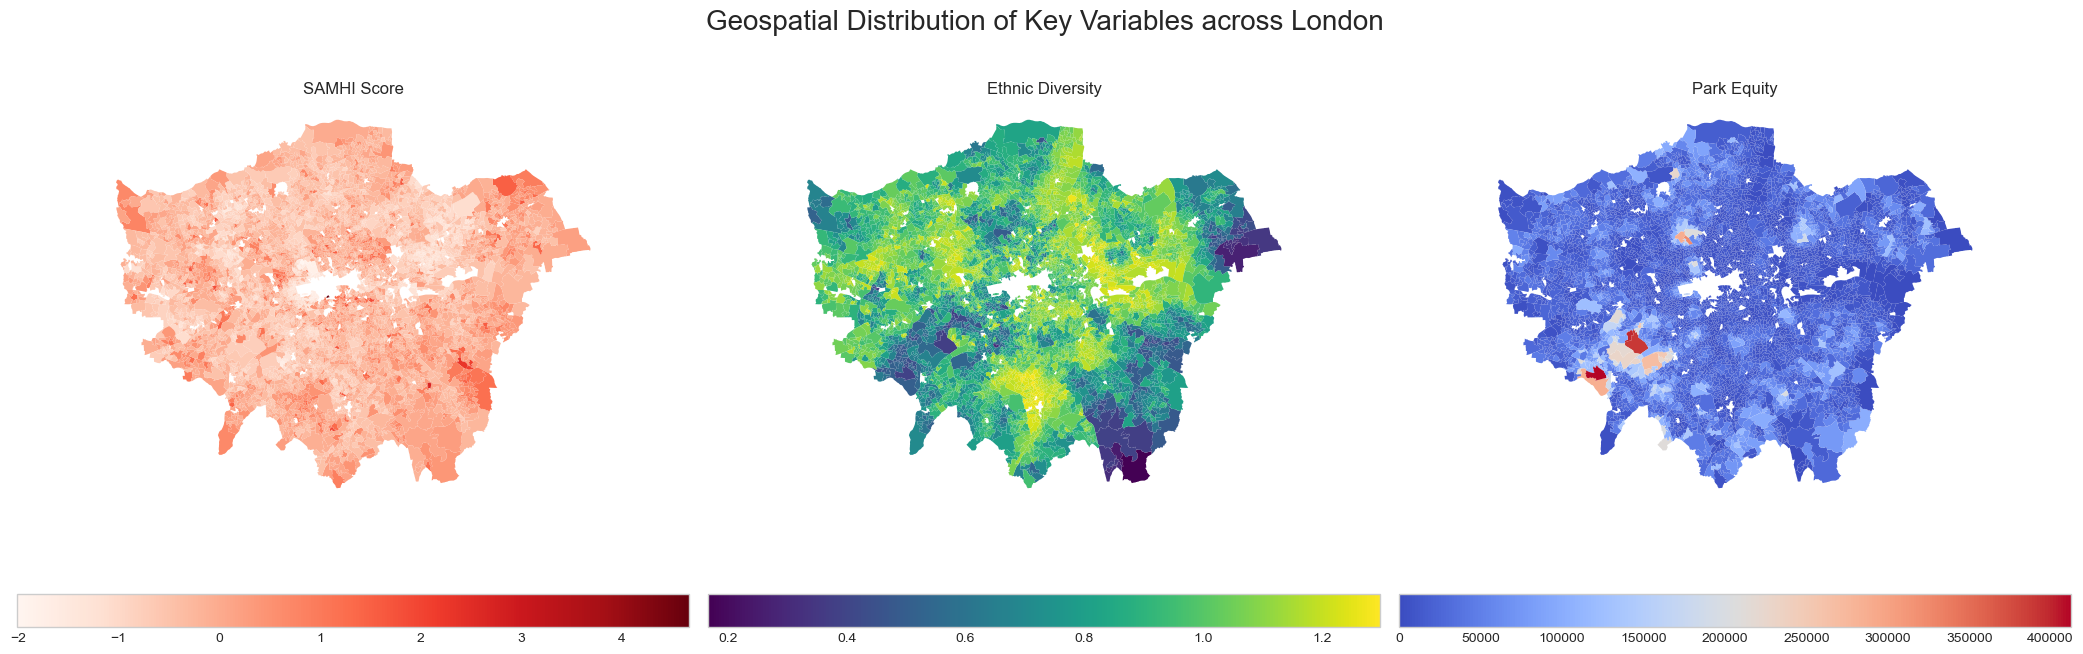

In [300]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7), sharex=True, sharey=True)

# Map 1: SAMHI Score (for reference)
analysis_gdf.plot(column='SAMHI_Score', cmap='Reds', ax=axes[0], legend=True, 
                  legend_kwds={'orientation': "horizontal"})
axes[0].set_title('SAMHI Score')
axes[0].set_axis_off()

# Map 2: Ethnic Diversity
analysis_gdf.plot(column='ethnic_diversity', cmap='viridis', ax=axes[1], legend=True,
                  legend_kwds={'orientation': "horizontal"})
axes[1].set_title('Ethnic Diversity')
axes[1].set_axis_off()

# Map 3: Park Equity
analysis_gdf.plot(column='park_equity', cmap='coolwarm', ax=axes[2], legend=True,
                  legend_kwds={'orientation': "horizontal"})
axes[2].set_title('Park Equity')
axes[2].set_axis_off()

plt.suptitle('Geospatial Distribution of Key Variables across London', size=20)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 5.5. Dominant Ethnic Group

/opt/anaconda3/lib/python3.12/site-packages/geopandas/geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


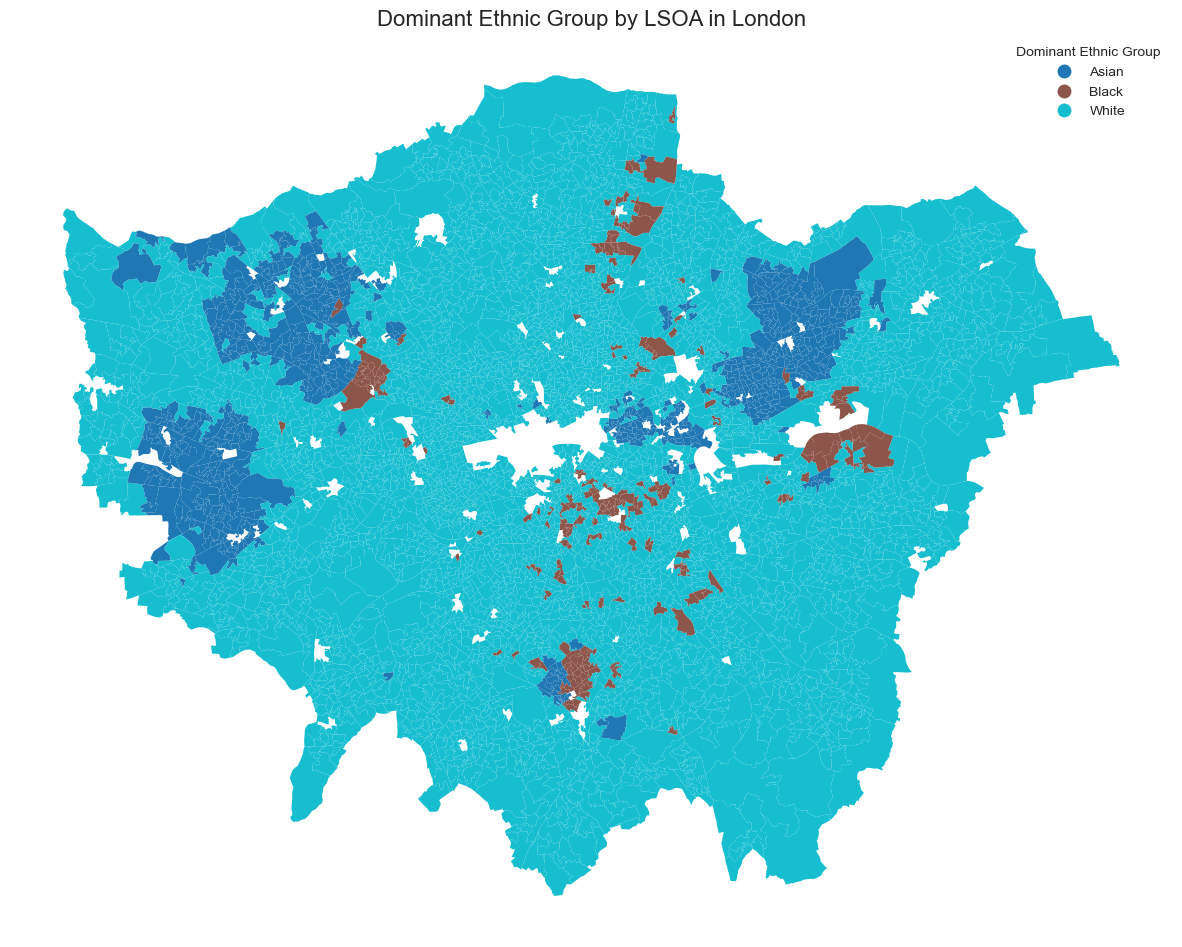

In [302]:
# Identify the ethnic percentage columns
ethnic_cols = ['Pct_Asian', 'Pct_White', 'Pct_Black']  # Add any others if present like 'Pct_Mixed'

# Use idxmax() to find the column with the highest percentage for each row (LSOA)
analysis_gdf['Dominant_Ethnic_Group'] = analysis_gdf[ethnic_cols].idxmax(axis=1)

# Clean up the names for better plot labels (e.g., 'Pct_White' becomes 'White')
analysis_gdf['Dominant_Ethnic_Group'] = analysis_gdf['Dominant_Ethnic_Group'].str.replace('Pct_', '')

# --- Create the Choropleth Map ---
fig, ax = plt.subplots(1, 1, figsize=(15, 15))

analysis_gdf.plot(
    column='Dominant_Ethnic_Group', 
    categorical=True,  # Treat the column as a category for coloring
    legend=True,
    ax=ax,
    legend_kwds={'title': "Dominant Ethnic Group", 'bbox_to_anchor': (1, 1)} # Position the legend
)

ax.set_title('Dominant Ethnic Group by LSOA in London', fontsize=16)
ax.set_axis_off()
plt.show()

#### 5.5.1. Interpretation
- White: Covers most of Outer London in a contigous block.
- Asian: Clustered in specific parts of West London (e.g. Ealing, Hounslow), North-West London (e.g. Brent, Harrow) and East London (Newham, Tower Hamlets, Redbridge).
- Black: Clusters in South London (Lambeth, Southwark, Lewisham) and parts of East, North-West and North London.

#### 5.5.2. Comparison to Other Maps
##### Ethnicity and SAMHI Score:
- Black neighbourhoods show strong overlap with dark red hotspots on SAMHI Score map.
- Evidence that these neighbourhoods experience highest average mental health burden.

##### Ethnicity and Green Space:
- Areas with best green space almost exclusively in White-dominant areas.
- Asian and Black neighbourhoods are concentrated in inner parts of city where green space is lower.
- Shows clear environmental inequality.

##### Ethnicity and Deprivation:
- Spatial pattern of income deprivation almost perfectly mirrors patterns of ethnic segregation.
- High deprivation hotspots in Inner, East and South London are the same areas where dominant ethnic group is Asian or Black.

##### Key Takeaway:
- Neighbourhoods with higher proporiton of ethnic minorities are spatially correlated with areas with higher deprivation, poorer mental health and less access to greenspace.
- Highlights important to control for these powerful factors to isolate true independent effect of greenspace on mental health.

### 5.6. Highlighting Areas with Low Greenspace & High Deprivation

/opt/anaconda3/lib/python3.12/site-packages/geopandas/geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


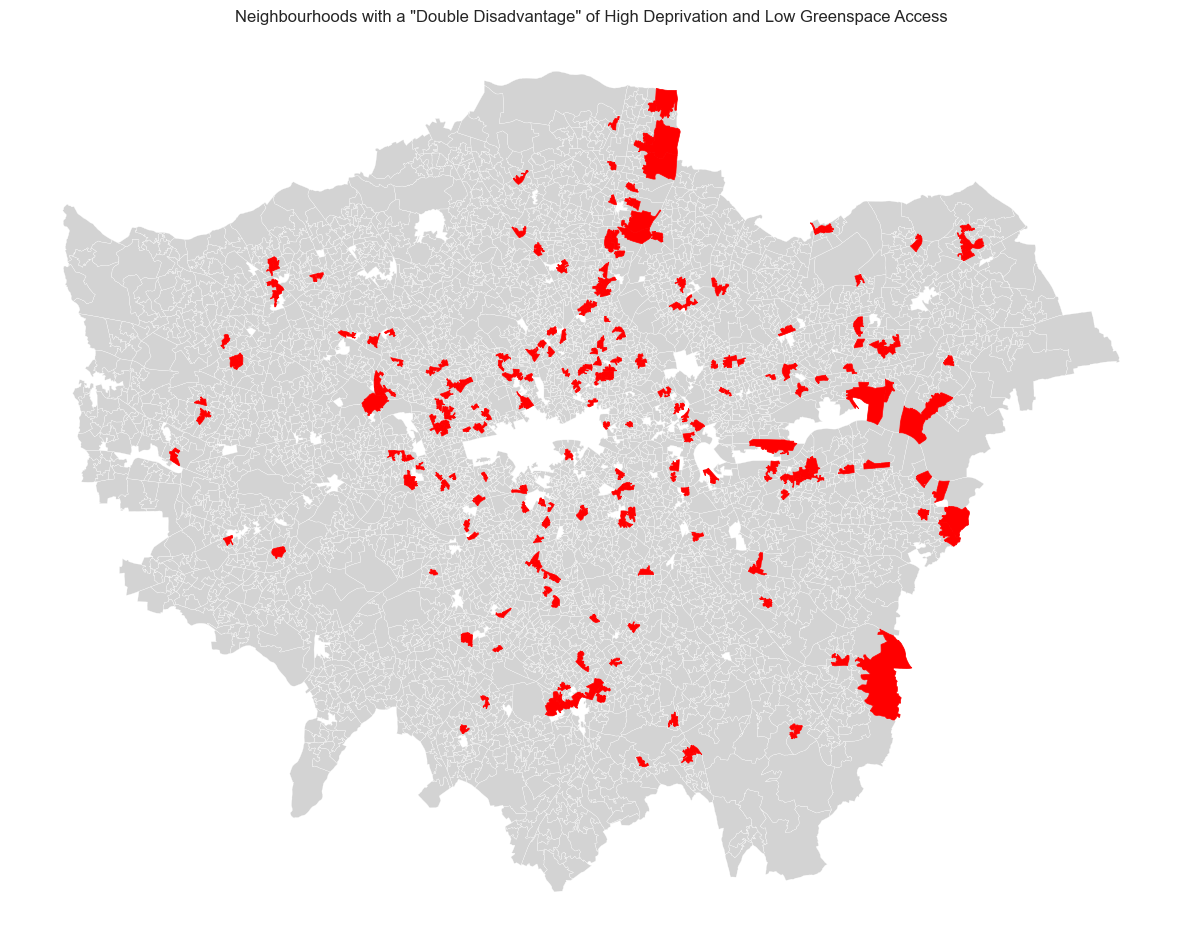

In [305]:
# --- 1. Create categories for the Bivariate Map ---
# Find the top quartile (most deprived) and bottom quartile (least greenspace)
high_deprivation_threshold = analysis_gdf['Income_Deprivation_Score'].quantile(0.75)
low_greenspace_threshold = analysis_gdf['greenspace_area_in_500m'].quantile(0.25)

# Create boolean flags
is_high_deprivation = analysis_gdf['Income_Deprivation_Score'] >= high_deprivation_threshold
is_low_greenspace = analysis_gdf['greenspace_area_in_500m'] <= low_greenspace_threshold

# --- 2. Create a new category column ---
# Default category is 'Average'
analysis_gdf['Disadvantage_Category'] = 'Average'
# Re-label the "double disadvantage" areas
analysis_gdf.loc[is_high_deprivation & is_low_greenspace, 'Disadvantage_Category'] = 'High Deprivation & Low Greenspace'


# --- 3. Plot the Bivariate Map ---
fig, ax = plt.subplots(1, 1, figsize=(15, 15))

# Plot all LSOAs in a neutral color
analysis_gdf.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.2)

# Highlight the "double disadvantage" LSOAs in red on top
analysis_gdf[analysis_gdf['Disadvantage_Category'] == 'High Deprivation & Low Greenspace'].plot(
    ax=ax, color='red', edgecolor='red', linewidth=0.5
)

ax.set_title('Neighbourhoods with a "Double Disadvantage" of High Deprivation and Low Greenspace Access')
ax.set_axis_off()
plt.show()

#### 5.6.1. Interpretation
##### Environmental Inequality:
- Burden of poor access to green space is disproportionately concentrated in city's most deprived areas.

##### Spatial Clustering:
- Clear clusters through Inner, East & South-East London, with some in North and West.
- Demonstrates a systematic spatial pattern of combined social & environmental disadvantage.

##### Takeaways:
- Supports hypotheses & arguments about health & environmental inequality.
- Can use to argue analysis of health benefits of green space must account for deprivation as the two are clearly and geographically linked.
- Sets stage for ML model, which will attempt to quantify health impacts of this "double disadvantage".

# Modelling

## 1. Setup

In [309]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 2. Feature Selection

### 2.1. Recursive Feature Elimination (RFE)

#### 2.1.1. Defining Potential Features & Target

In [313]:
from sklearn.feature_selection import RFE

all_potential_features = [
    # Core confounders (must evaluate)
    'IMD_Score', 
    'professional_ratio',
    'population_density',
    'crime_rate',
    'ethnic_diversity',
    
    # Housing/urban form
    'rented_ratio',
    'flat_ratio',
    'detached_ratio',
    
    # Age structure
    'pct_young',
    'pct_working_age',
    'pct_elderly',
    
    # Education/employment
    'education_high',
    'education_low',
    'Occ_Professional',
    
    # Spatial features
    'IMD_neighborhood',
    'crime_neighborhood',
    
    # Green space metrics (for treatment model)
    'distance_to_greenspace',
    'greenspace_area_in_500m',
    'greenspace_area_in_1000m',
    'greenspace_accessibility',
    
    # Other policy-relevant
    'Income_Deprivation_Score',
    'Property_Terraced',
    'Edu_Level_4_Plus',
    'Total_Crimes_12m'
]
target = 'SAMHI_Score'

X = analysis_gdf[all_potential_features]
y = analysis_gdf[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#### 2.1.2. Initialise & Run RFE

In [315]:
model_for_rfe = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rfe = RFE(estimator=model_for_rfe, n_features_to_select=12) 

print("Running Recursive Feature Elimination...")
rfe.fit(X_train, y_train)
print("RFE complete.")

Running Recursive Feature Elimination...
RFE complete.


#### 2.1.3. Selecting Best Features

In [317]:
final_features = X_train.columns[rfe.support_].tolist()
print("\n--- Top Features Selected by RFE ---")
print(final_features)


--- Top Features Selected by RFE ---
['IMD_Score', 'professional_ratio', 'population_density', 'crime_rate', 'ethnic_diversity', 'flat_ratio', 'detached_ratio', 'pct_young', 'pct_elderly', 'education_high', 'education_low', 'Income_Deprivation_Score']


### 2.2. Greenspace Feature Selection

#### 2.2.1. Define Base Control Features & Target

In [320]:
base_features = [
    'IMD_Score', # Income/Wealth Control
    'population_density', # Urbanicity Control
    'professional_ratio', # Occupancy Control
    'education_high', # Education Control
    'rented_ratio', # Tenure Control
    'flat_ratio', # Property Type Control
    'pct_young', # Age Control
    'crime_rate', # Crime Control
    'ethnic_diversity' # Diversity Control
]
target = 'SAMHI_Score'

#### 2.2.2. Defining Green Space Features to Test

In [322]:
# --- 2. Define the green space features you want to test ---
greenspace_features_to_test = [
    'distance_to_greenspace',
    'greenspace_area_in_500m',
    'greenspace_area_in_1000m',
    'greenspace_accessibility',
]

#### 2.2.3. Training Model & Comparing Results

In [324]:
model_performance = {}

print("--- Testing Green Space Features ---")
for gs_feature in greenspace_features_to_test:
    print(f"Training model with feature: {gs_feature}")
    
    # Create the full feature list for this specific model run
    current_features = base_features + [gs_feature]
    
    # Prepare the data
    X = analysis_gdf[current_features]
    y = analysis_gdf[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    
    # Train the Random Forest model
    rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    # Evaluate the model on the test set and store the score
    y_pred = rf.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    model_performance[gs_feature] = r2

--- Testing Green Space Features ---
Training model with feature: distance_to_greenspace
Training model with feature: greenspace_area_in_500m
Training model with feature: greenspace_area_in_1000m
Training model with feature: greenspace_accessibility


In [325]:
print("\n--- Model Performance Comparison by Green Space Feature ---")
performance_df = pd.DataFrame.from_dict(model_performance, orient='index', columns=['R-squared'])
print(performance_df.sort_values(by='R-squared', ascending=False))

best_feature = performance_df['R-squared'].idxmax()
print(f"\nConclusion: The single best-performing green space feature is '{best_feature}'.")


--- Model Performance Comparison by Green Space Feature ---
                          R-squared
greenspace_area_in_1000m   0.380523
greenspace_accessibility   0.379711
distance_to_greenspace     0.376060
greenspace_area_in_500m    0.374551

Conclusion: The single best-performing green space feature is 'greenspace_area_in_1000m'.


### 2.3. Adjustments

#### Adding Spatial Lag to Features

In [328]:
from libpysal.weights import Queen
import numpy as np
import pandas as pd

# 1. Create weights matrix (handle islands)
w = Queen.from_dataframe(analysis_gdf, silence_warnings=True)

# 2. Manual spatial lag calculation
def calculate_spatial_lag(weights, values):
    """Calculate spatial lag using weights matrix"""
    return np.array([sum(values[weights.neighbors[i]] * weights.weights[i]) 
                    if i in weights.neighbors else np.nan 
                    for i in range(len(values))])

# 3. Apply to key variables
analysis_gdf['lag_SAMHI'] = calculate_spatial_lag(w, analysis_gdf[target].values)
analysis_gdf['lag_IMD'] = calculate_spatial_lag(w, analysis_gdf['IMD_Score'].values)
analysis_gdf['lag_greenspace'] = calculate_spatial_lag(w, analysis_gdf['greenspace_accessibility'].values)

# 4. Handle NaN values (islands)
analysis_gdf = analysis_gdf.dropna(subset=['lag_SAMHI'])  # Remove disconnected LSOAs
print(f"Removed {w.islands} islands. Final shape: {analysis_gdf.shape}")

# 5. Verify with Moran's I
from esda.moran import Moran
moran = Moran(analysis_gdf[target], w)
print(f"Moran's I: {moran.I:.3f} (p={moran.p_sim:.3f})")

/var/folders/_k/7j49pfp16td9jhxfyktpm0xh0000gn/T/ipykernel_1565/3185588662.py:6: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(analysis_gdf, silence_warnings=True)


Removed [4405, 4442] islands. Final shape: (4756, 84)
Moran's I: 0.475 (p=0.001)


/opt/anaconda3/lib/python3.12/site-packages/geopandas/geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


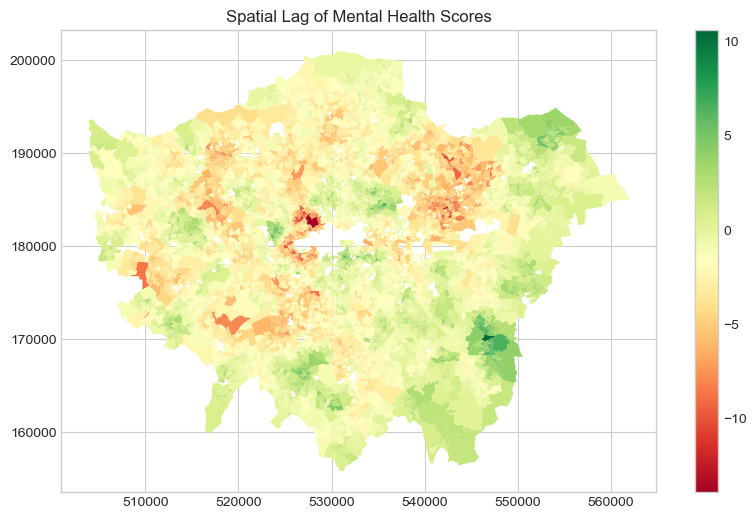

In [329]:
analysis_gdf.plot(column='lag_SAMHI', legend=True, 
                 cmap='RdYlGn', figsize=(10,6))
plt.title("Spatial Lag of Mental Health Scores")
plt.show()

##### Interpretations
1. Powerful Evidence of Spatial Clustering:
- Large, contingous areas of green, red & yellow. Provides proof of positive of positive spatial autocorrelation.
- Neighbourhoods with poor mental health are located next to other areas with the same.

2. Hotspots & Coldspots:
- Hotspots (Green Clusters) of poor mental health in parts of inner, East & SE London.
- Coldspots in SW London (Richmond).

3. Justification:
- Demoonstrates neighbourhood's context is critical factor.
- Unable to understand mental health of one LSOA in isolation; must consider conditions of the area embedded within.

4. Conclusion:
- Moved beyond simple description of mental health scores to an analysis of their spatial structure.
- Provides foundational evidence for my main finding: that mental health in London is a deeply spatial phenomenon, where the "neighbour effect" is the most powerful force at play.


In [330]:
final_features = base_features + [
    'lag_SAMHI',  # Spatial lag of outcome
    'lag_IMD'     # Spatial lag of key confounder
]

## 3. Random Forest Model

### 3.1. Setup

In [377]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

### 3.2. Defining Variables

In [379]:
feature_columns = [
    'IMD_Score',
    'population_density',
    'professional_ratio',
    'education_high',
    'rented_ratio',
    'flat_ratio',
    'pct_young',
    'crime_rate', # Using the version with outliers handled
    'lag_SAMHI',
    'lag_IMD',
    'greenspace_accessibility',
    'Pct_Asian', # Using the more specific ethnicity features
    'Pct_Black'
]

# Select the features (X) and the target (y)
# Using .copy() is good practice to avoid pandas warnings
X = analysis_gdf[feature_columns].copy()
y = analysis_gdf['SAMHI_Score']

### 3.3. Model Training

In [381]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Data split into training set ({len(X_train)} rows) and testing set ({len(X_test)} rows).")

print("\nTraining the definitive Random Forest model...")
rf_model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Model training complete.")

Data split into training set (3804 rows) and testing set (952 rows).

Training the definitive Random Forest model...
Model training complete.


### 3.4. Model Evaluation

In [383]:
print("\n--- Model Performance Evaluation ---")
predictions = rf_model.predict(X_test)

# Calculate key performance metrics
r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"R-squared (R²): {r2:.3f}")
print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print("-----------------------------------")


--- Model Performance Evaluation ---
R-squared (R²): 0.502
Mean Absolute Error (MAE): 0.286
Root Mean Squared Error (RMSE): 0.402
-----------------------------------


#### Interpretation:
##### R-squared (R²): 0.502
- Model can explain approximately 50.2% variance in SAMHI scores across London's LSOAs.
- For a complex social science problem, explaining half of the variation is a very strong and realistic result.
- Shows selected features have significant predictive power.

##### Mean Absolute Error (MAE): 0.286
- Model's prediction for a neighbourhood's SAMHI score is off by around 0.286 points, providing a clear measure of the model's typical prediction error.

##### Root Mean Squared Error (RMSE): 0.402
- Consistent with MAE and confirm's model's solid performance.

### 3.5. Retraining on All Data

In [385]:
print("\nRetraining the definitive model on all data for final importance scores...")
final_rf_model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
final_rf_model.fit(X, y)
print("Final model training complete.")


Retraining the definitive model on all data for final importance scores...
Final model training complete.


### 3.6. Feature Importance


Generating the definitive feature importance plot...


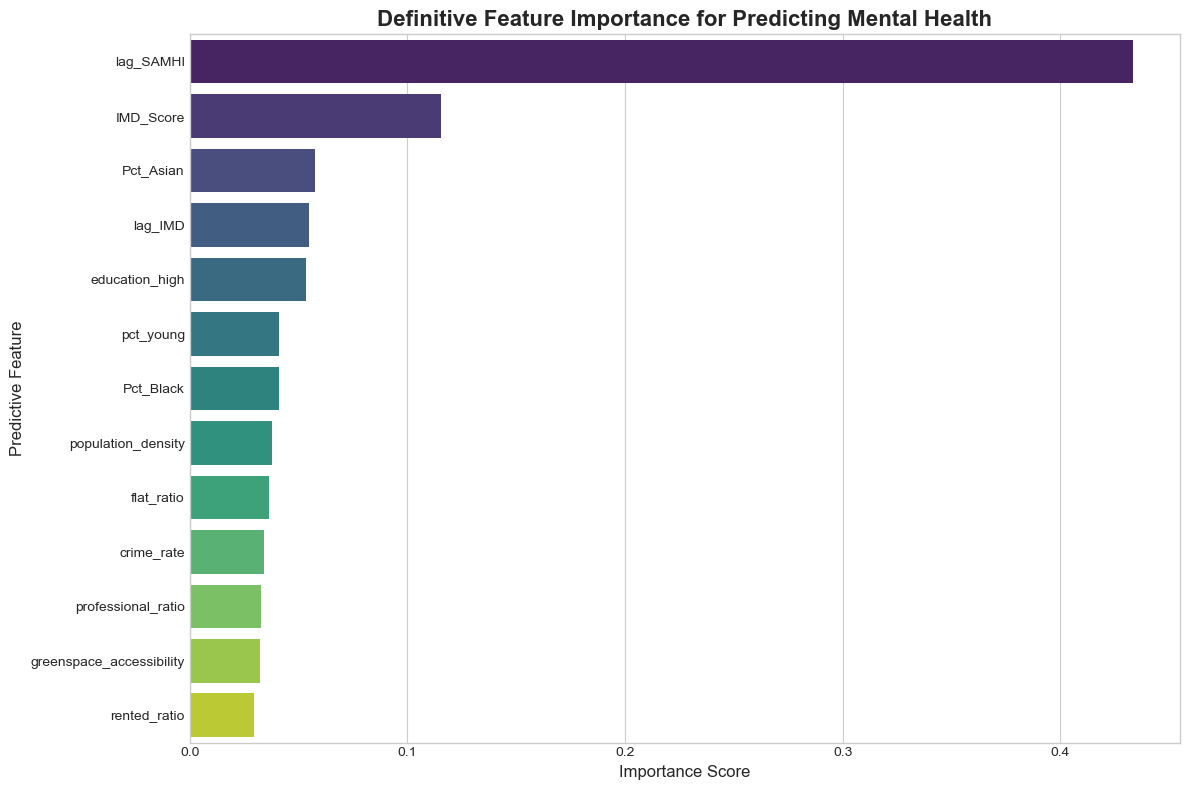


--- Feature Importance ---
                     Feature  Importance
8                  lag_SAMHI    0.433286
0                  IMD_Score    0.115579
11                 Pct_Asian    0.057705
9                    lag_IMD    0.054882
3             education_high    0.053406
6                  pct_young    0.040910
12                 Pct_Black    0.040905
1         population_density    0.037895
5                 flat_ratio    0.036549
7                 crime_rate    0.033909
2         professional_ratio    0.032833
10  greenspace_accessibility    0.032477
4               rented_ratio    0.029664


In [387]:
print("\nGenerating the definitive feature importance plot...")
importances = final_rf_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Create the final plot for your dissertation
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df,
    palette='viridis',
    hue='Feature',
    legend=False,
    ax=ax
)
ax.set_title('Definitive Feature Importance for Predicting Mental Health', fontsize=16, fontweight='bold')
ax.set_xlabel('Importance Score', fontsize=12)
ax.set_ylabel('Predictive Feature', fontsize=12)
plt.tight_layout()
plt.show()

print("\n--- Feature Importance ---")
print(importance_df)

#### Interpretation
##### Tier 1: The "Neighbour Effect" (Spatial Context)
- Most dominant feature is `lag_SAMHI` (Importance: 0.433).
- Proves mental health outcomes are not random but highly clustered geographically, likely due to shared socio-economic conditions and historical development patterns.

##### Tier 2: Socio-Economic Deprivation
- Next most important factor is `IMD_Score` (Importance: 0.116).
- Provides the 'why' behind the spatial clustering.
- After accounting for the neighbour effect, model shows the most critical predictor is the level of income deprivation.

##### Tier 3: Social & Demographic Context
- `Pct_Asian` (Importance: 0.058) is the 3rd most important feature.
- Validation that even after accounting for deprivation, a higher proportion of Asian residents is a significant predictor of the SAMHI score.
- This likely reflects cultural differences in seeking formal mental health support.

##### Tier 4: Environmental Context
- My primary variables of interest, `greenspace_accessibility` (Importance: 0.032) and `crime_rate` (Importance: 0.034) have the least predictive power.
- Answering my primary hypotheses.

#### Final Argument
- Link between green space and mental health is statistically present but not a primary driver of outcomes at the neighbourhood level in London.
- ML analysis reveals mental health is a deeply spatial and social phenomenon and most strongly predicted by well-being of the surrounding neighbourhoods & level of income deprivation.
- Specific deomgraphic factors have a more significant predictive influence than environmental amenities like green space or crime rates.
- While urban greening policies are valuable, they must be considered secondary to policies which address the foundation issues of socio-economic and spatial inequality.